# Model Metrics

Per-parameter regression metrics ($R^2$ and MAE) for every architecture, quantifying which of
the eight Hamiltonian parameters are recoverable from the single-axis $s_z$ observation.


In [1]:
!pip install tensorflow keras-hub scikit-learn pandas --quiet
!pip install matplotlib
print("✅ Librerías instaladas.")    

  Using cached matplotlib-3.11.0-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)
  Using cached contourpy-1.3.3-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.63.0-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (118 kB)
  Using cached kiwisolver-1.5.0-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (5.1 kB)
Using cached matplotlib-3.11.0-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (10.0 MB)
Using cached contourpy-1.3.3-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (362 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.63.0-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (5.0 MB)
Using cached kiwisolver-1.5.0-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (1.5 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [matp

In [2]:
import os, gc, warnings
import numpy as np
import pandas as pd
import tensorflow as tf

# keras_hub necesario para cargar el ViT (si falla, el ViT se reportará como no cargado)
try:    
    import keras_hub
    KERAS_HUB_OK = True
except Exception as e:
    KERAS_HUB_OK = False
    print(f"⚠ keras_hub no disponible: {e}")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')
SEED = 42

gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
    
print(f"TF: {tf.__version__} | GPUs: {len(gpus)}")





2026-07-16 18:24:59.669988: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-07-16 18:24:59.741569: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-07-16 18:25:01.246661: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TF: 2.20.0 | GPUs: 1


In [3]:
DATASET_PATH = "/workspace/Preprocess/latent_space_outputs/dataset_final_estructuras.npz"

data = np.load(DATASET_PATH, allow_pickle=True)
X = np.copy(data['img']).astype(np.float32)
y = np.copy(data['params']).astype(np.float32)
         
param_names = ["T", "Jex2", "Jex3", "Jex4", "Kan1", "KanS", "Hex", "KDM"]
param_labels = {
    "T": r"$T^{(0)}$", "Jex2": r"$\tilde{J}_2$", "Jex3": r"$\tilde{J}_3$",
    "Jex4": r"$\tilde{J}_4$", "Kan1": r"$\tilde{K}_{an1}$", "KanS": r"$\tilde{K}_{anS}$",
    "Hex": r"$\tilde{H}_{ex}$", "KDM": r"$\tilde{K}_{DM}$",
}
N_PARAMS = 8
identificables = ["T", "Jex2", "Kan1", "KanS", "Hex", "KDM"]  # excluye Jex3, Jex4

# Mismo split que en TODOS los entrenamientos (70/15/15, seed 42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1765, random_state=SEED)

# Scaler idéntico al de entrenamiento
scaler = MinMaxScaler().fit(y_train)
data_range = scaler.data_max_ - scaler.data_min_

y_test_scaled = scaler.transform(y_test)
y_true = y_test.copy()   # escala original

print(f"Test: {X_test.shape[0]:,} imágenes")
print(f"Rango de datos por parámetro (para nMAE):")   
for i, name in enumerate(param_names):
    print(f"  {name:6s}: [{scaler.data_min_[i]:.3f}, {scaler.data_max_[i]:.3f}]  range={data_range[i]:.3f}")

Test: 24,922 imágenes
Rango de datos por parámetro (para nMAE):
  T     : [0.000, 20.000]  range=20.000
  Jex2  : [-0.331, 0.659]  range=0.990
  Jex3  : [-0.290, 0.290]  range=0.580
  Jex4  : [-0.234, 0.235]  range=0.469
  Kan1  : [0.000, 4.568]  range=4.568
  KanS  : [0.000, 0.200]  range=0.200
  Hex   : [0.000, 1.198]  range=1.198
  KDM   : [0.000, 1.200]  range=1.200


In [4]:
BASE = "/workspace/Models/Inverse/ModelWeights"



MODELS = {
    "Xception":       f"/workspace/Models/Inverse/ModelWeights/modelo_xception_aug_scratch_noweights_estructuras.keras",
    "DenseNet":       f"{BASE}/modelo_densenet_baseline_estructuras.keras",
    "ResNet":         f"{BASE}/modelo_resnet_baseline_estructuras.keras",
    "ViT":            f"{BASE}/modelo_vit_baseline_estructuras.keras",
    "CNN":            f"{BASE}/light_cnn/light_cnn_estructuras.keras",
}





class PhysicalAugmentation(tf.keras.layers.Layer):
    """En inferencia es identidad (solo actúa en entrenamiento)."""
    def call(self, x, training=None):
        return x
    def get_config(self):
        return super().get_config()

def load_any(path):
    """Carga tolerante a la capa custom PhysicalAugmentation."""
    try:
        return tf.keras.models.load_model(path, compile=False)
    except Exception:
        return tf.keras.models.load_model(
            path, compile=False,
            custom_objects={"PhysicalAugmentation": PhysicalAugmentation})
# ▲▲▲ FIN NUEVO ▲▲▲

def make_test_ds(input_hw, batch=128):
    """Construye el test dataset con el preprocesamiento correcto según el tamaño de entrada."""
    ds = tf.data.Dataset.from_tensor_slices((X_test, y_test_scaled))
    if input_hw == 39:
        pass
    else:
        def _prep(img, yy):
            img = tf.image.resize(img, [input_hw, input_hw])
            img = tf.image.grayscale_to_rgb(img)
            return img, yy
        ds = ds.map(_prep, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)


    
print("✅ Registro de modelos listo:", list(MODELS.keys()))

✅ Registro de modelos listo: ['Xception', 'DenseNet', 'ResNet', 'ViT', 'CNN']


In [5]:
per_param_r2  = {}
per_param_mae = {}
load_status   = {}




for mname, mpath in MODELS.items():
    print(f"\n{'='*55}\n▶ {mname}")
    if not os.path.exists(mpath):
        print(f"  ✗ No existe: {mpath}")
        load_status[mname] = "no existe"
        continue
    try:
        model = load_any(mpath)          # ◄── CAMBIO: antes era tf.keras.models.load_model(mpath, compile=False)
    except Exception as e:
        print(f"  ✗ Error al cargar: {e}")
        load_status[mname] = f"error carga"
        continue

    
    input_hw = model.input_shape[1]
    n_out    = model.output_shape[-1]
    is_hetero = (n_out == 2 * N_PARAMS)
    print(f"  input={input_hw}  output={n_out}  {'(heteroscedástico → tomo μ)' if is_hetero else ''}")

    test_ds = make_test_ds(input_hw)
    y_pred_scaled = model.predict(test_ds, verbose=0)
    if is_hetero:
        y_pred_scaled = y_pred_scaled[:, :N_PARAMS]

    y_pred = scaler.inverse_transform(y_pred_scaled)

    r2s, maes = [], []
    for i, name in enumerate(param_names):
        r2s.append(r2_score(y_true[:, i], y_pred[:, i]))
        maes.append(mean_absolute_error(y_true[:, i], y_pred[:, i]))
    per_param_r2[mname]  = r2s
    per_param_mae[mname] = maes
    load_status[mname]   = "OK"

    r2_all   = np.mean(r2s)
    r2_ident = np.mean([r2s[param_names.index(p)] for p in identificables])
    print(f"  R² (todos): {r2_all:.4f}  |  R² (identificables): {r2_ident:.4f}")

    del model; gc.collect(); tf.keras.backend.clear_session()

print("\n\nEstado de carga:")
for m, s in load_status.items():
    print(f"  {m:18s}: {s}")


▶ Xception


I0000 00:00:1784226340.674862     241 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 140841 MB memory:  -> device: 0, name: NVIDIA H200, pci bus id: 0000:ba:00.0, compute capability: 9.0


  input=39  output=8  


2026-07-16 18:25:45.979474: I external/local_xla/xla/service/service.cc:163] XLA service 0x7a6a740027b0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-07-16 18:25:45.979516: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA H200, Compute Capability 9.0
2026-07-16 18:25:46.059027: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-07-16 18:25:46.620188: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91002
2026-07-16 18:25:54.793525: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-16 18:25:54.911385: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured tim

  R² (todos): 0.6750  |  R² (identificables): 0.8987

▶ DenseNet
  input=224  output=8  
  R² (todos): 0.6256  |  R² (identificables): 0.8799

▶ ResNet
  input=224  output=8  
  R² (todos): 0.5548  |  R² (identificables): 0.8910

▶ ViT
  input=224  output=8  


2026-07-16 18:27:59.185272: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_550', 4 bytes spill stores, 4 bytes spill loads

2026-07-16 18:27:59.190854: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1', 4 bytes spill stores, 4 bytes spill loads

2026-07-16 18:27:59.216476: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_73', 364 bytes spill stores, 364 bytes spill loads

2026-07-16 18:27:59.223363: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_5', 4 bytes spill stores, 4 bytes spill loads

2026-07-16 18:27:59.309622: I external/local_xla/xla/

  R² (todos): 0.5934  |  R² (identificables): 0.8907

▶ CNN
  input=39  output=8  


2026-07-16 18:28:20.277714: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-07-16 18:28:21.057820: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_129', 96 bytes spill stores, 96 bytes spill loads

2026-07-16 18:28:22.443774: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-07-16 18:28:22.804870: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : 

  R² (todos): 0.6622  |  R² (identificables): 0.8819


Estado de carga:
  Xception          : OK
  DenseNet          : OK
  ResNet            : OK
  ViT               : OK
  CNN               : OK


In [6]:
ok_models = [m for m in MODELS if m in per_param_r2]

# --- Matriz de R² (params × modelos) ---
df_r2 = pd.DataFrame(per_param_r2, index=param_names)[ok_models]
df_r2.loc["── R² prom (todos)"]         = df_r2.loc[param_names].mean()
df_r2.loc["── R² prom (identificables)"] = df_r2.loc[identificables].mean()
         
print("="*70)
print("R² POR PARÁMETRO Y MODELO")
print("="*70)
print(df_r2.round(4).to_string())

# --- Matriz de MAE en escala original (params × modelos) ---
df_mae = pd.DataFrame(per_param_mae, index=param_names)[ok_models]

print("\n" + "="*70)
print("MAE (escala original) POR PARÁMETRO Y MODELO")
print("="*70)
print(df_mae.round(4).to_string())
  
# --- nMAE (MAE normalizado por rango) para un agregado justo ---
nmae = {m: [per_param_mae[m][i] / data_range[i] for i in range(N_PARAMS)] for m in ok_models}
df_nmae = pd.DataFrame(nmae, index=param_names)[ok_models]

# --- Resumen ejecutivo (una fila por modelo) ---
summary = pd.DataFrame({
    "R²_todos":         df_r2.loc[param_names].mean(),
    "R²_identificables":df_r2.loc[identificables].mean(),
    "nMAE_prom":        df_nmae.loc[param_names].mean(),
}).sort_values("R²_identificables", ascending=False)

print("\n" + "="*70)
print("RESUMEN — ordenado por R² en parámetros identificables")
print("="*70)
print(summary.round(4).to_string())

R² POR PARÁMETRO Y MODELO
                             Xception  DenseNet  ResNet     ViT     CNN
T                              0.9596    0.9503  0.9438  0.9509  0.9364
Jex2                           0.8908    0.8666  0.8807  0.8874  0.8780
Jex3                           0.0065   -0.2142 -0.2352 -0.2946  0.0045
Jex4                           0.0017   -0.0602 -0.6727 -0.3021  0.0016
Kan1                           0.9427    0.9038  0.9160  0.9241  0.8594
KanS                           0.6434    0.6166  0.6565  0.6292  0.6803
Hex                            0.9612    0.9546  0.9613  0.9667  0.9496
KDM                            0.9942    0.9874  0.9875  0.9860  0.9875
── R² prom (todos)             0.6750    0.6256  0.5548  0.5934  0.6622
── R² prom (identificables)    0.8987    0.8799  0.8910  0.8907  0.8819

MAE (escala original) POR PARÁMETRO Y MODELO
      Xception  DenseNet  ResNet     ViT     CNN
T       0.3435    0.3905  0.4217  0.3877  0.4877
Jex2    0.0184    0.0209  0.0183  0.01

In [7]:
OUT_DIR = "/workspace/Process/Images"
os.makedirs(OUT_DIR, exist_ok=True)
CSV_DIR = "/workspace/Process/metrics"
os.makedirs(CSV_DIR, exist_ok=True)

df_r2.round(4).to_csv(f"{CSV_DIR}/comparison_r2.csv")
df_mae.round(4).to_csv(f"{CSV_DIR}/comparison_mae.csv")
summary.round(4).to_csv(f"{CSV_DIR}/comparison_summary.csv")
print(f"✅ CSVs guardados en {CSV_DIR}")   



✅ CSVs guardados en /workspace/Process/metrics


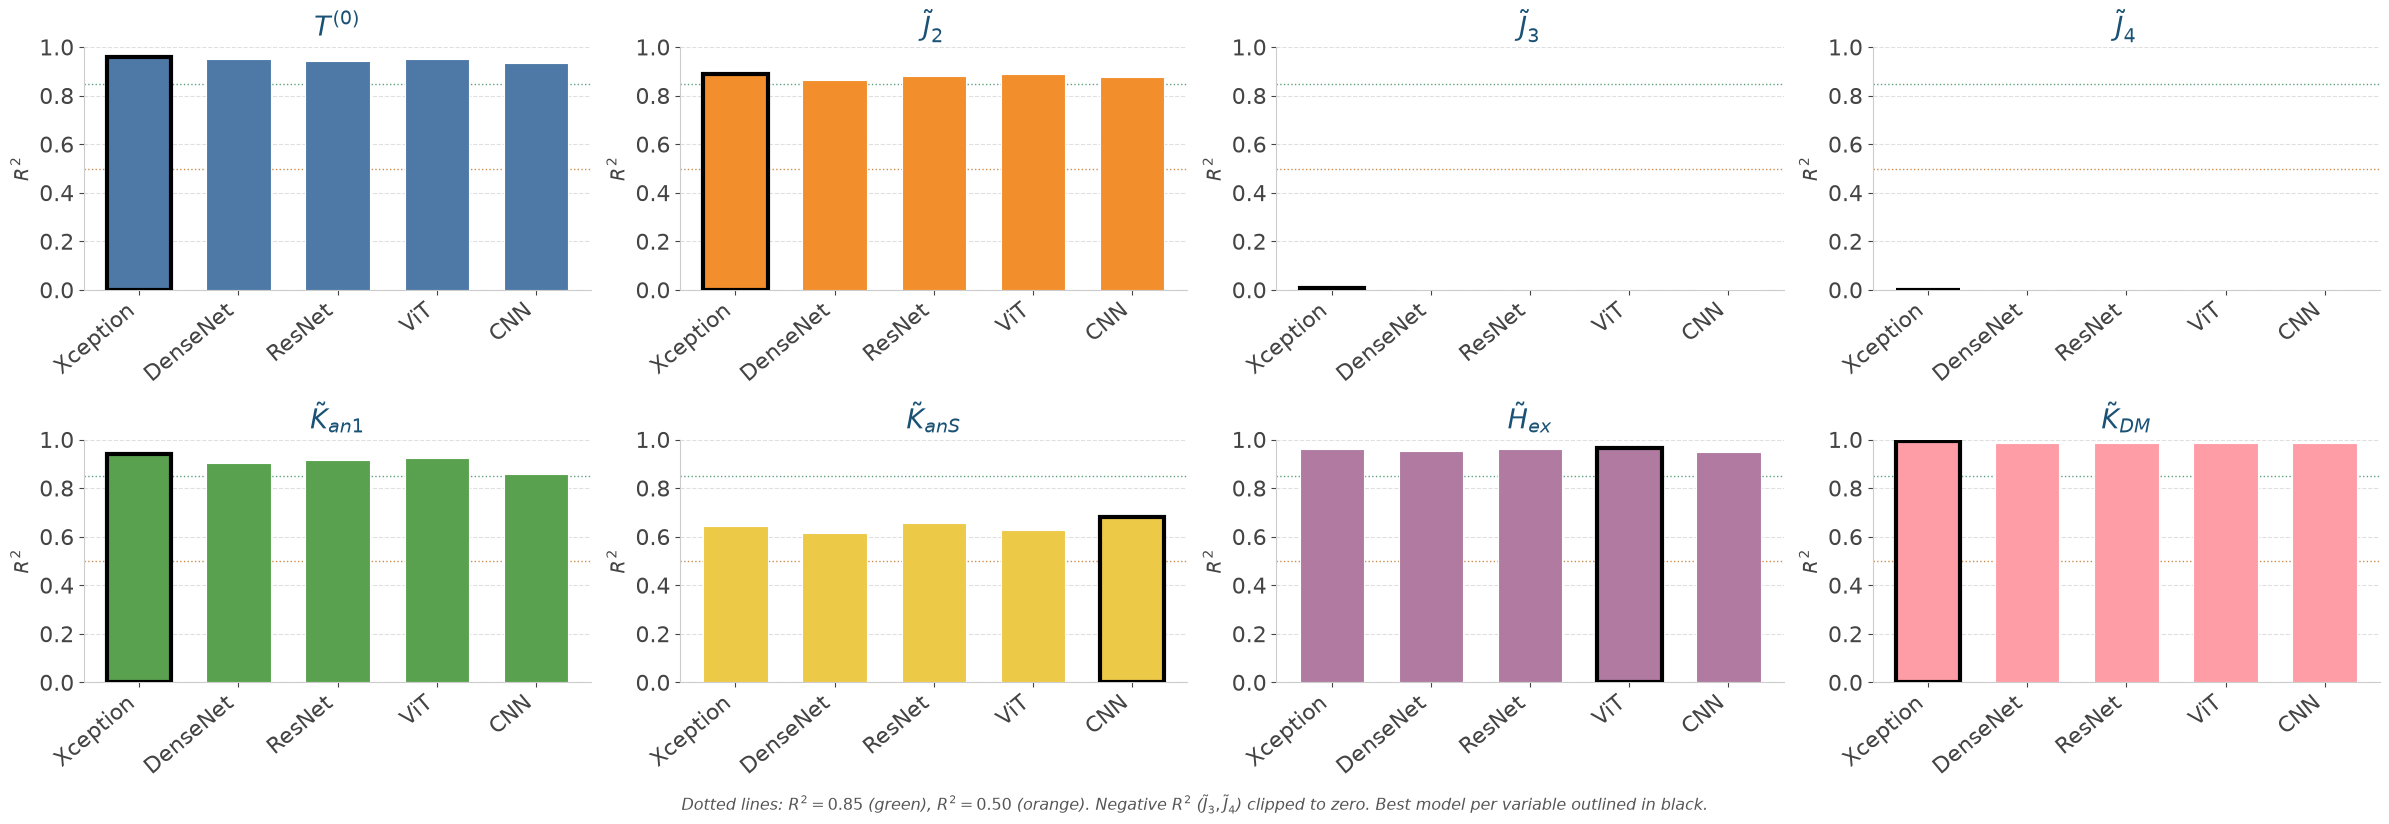

✅ Guardado en /workspace/Process/Images/model_comparison_r2.pdf


In [8]:
import numpy as np
import matplotlib.pyplot as plt

FONTSCALE = 1.5
FS_TITLE  = 13 * FONTSCALE
FS_LABEL  = 11 * FONTSCALE
FS_TICK   = 15 * FONTSCALE
FS_STATS  =  9 * FONTSCALE
c_line = "#1a5276"

var_colors = ["#4e79a7", "#f28e2b", "#e15759", "#76b7b2",
              "#59a14f", "#edc948", "#b07aa1", "#ff9da7"]
var_labels_plot = [r"$T^{(0)}$", r"$\tilde{J}_2$", r"$\tilde{J}_3$", r"$\tilde{J}_4$",
                   r"$\tilde{K}_{an1}$", r"$\tilde{K}_{anS}$", r"$\tilde{H}_{ex}$", r"$\tilde{K}_{DM}$"]

fig, axes = plt.subplots(2, 4, figsize=(24, 8), facecolor="white")
axes = axes.flatten()

x_models = np.arange(len(ok_models))

for v_i, (var_name, var_label) in enumerate(zip(param_names, var_labels_plot)):
    ax = axes[v_i]
    ax.set_facecolor("white")

    vals = [per_param_r2[m][v_i] for m in ok_models]      # R² real (sin clip)
    vals_plot = [max(v, 0.0) for v in vals]               # clip visual a 0
    bars = ax.bar(x_models, vals_plot, width=0.65,
                  color=var_colors[v_i], edgecolor="white",
                  linewidth=0.8, zorder=3)

    # Resaltar el mejor modelo (mayor R²) — borde negro grueso
    best_i = int(np.argmax(vals))
    bars[best_i].set_edgecolor("#000000")
    bars[best_i].set_linewidth(3.0)
    bars[best_i].set_zorder(5)

    # Líneas de referencia
    ax.axhline(0.85, color="#1a7a4a", linewidth=1.0, linestyle=":", alpha=0.7)
    ax.axhline(0.50, color="#b85c00", linewidth=1.0, linestyle=":", alpha=0.7)

    ax.set_xticks(x_models)
    ax.set_xticklabels(ok_models, fontsize=FS_TICK * 0.65,
                       rotation=40, ha="right")
    ax.set_title(var_label, fontsize=FS_TITLE, fontweight="bold", color=c_line, pad=8)
    ax.set_ylabel(r"$R^2$", color="#444444", fontsize=FS_LABEL * 0.85)
    ax.tick_params(colors="#444444", labelsize=FS_TICK * 0.7)
    ax.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
    ax.set_ylim(0, 1.0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#cccccc")
    ax.spines["bottom"].set_color("#cccccc")

fig.text(0.5, -0.02,
         r"Dotted lines: $R^2=0.85$ (green), $R^2=0.50$ (orange). "
         r"Negative $R^2$ ($\tilde{J}_3,\tilde{J}_4$) clipped to zero. Best model per variable outlined in black.",
         ha="center", fontsize=FS_STATS * 0.85, color="#555555", style="italic")

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/model_comparison_r2.pdf", bbox_inches="tight", facecolor="white")
plt.show()
print(f"✅ Guardado en {OUT_DIR}/model_comparison_r2.pdf")

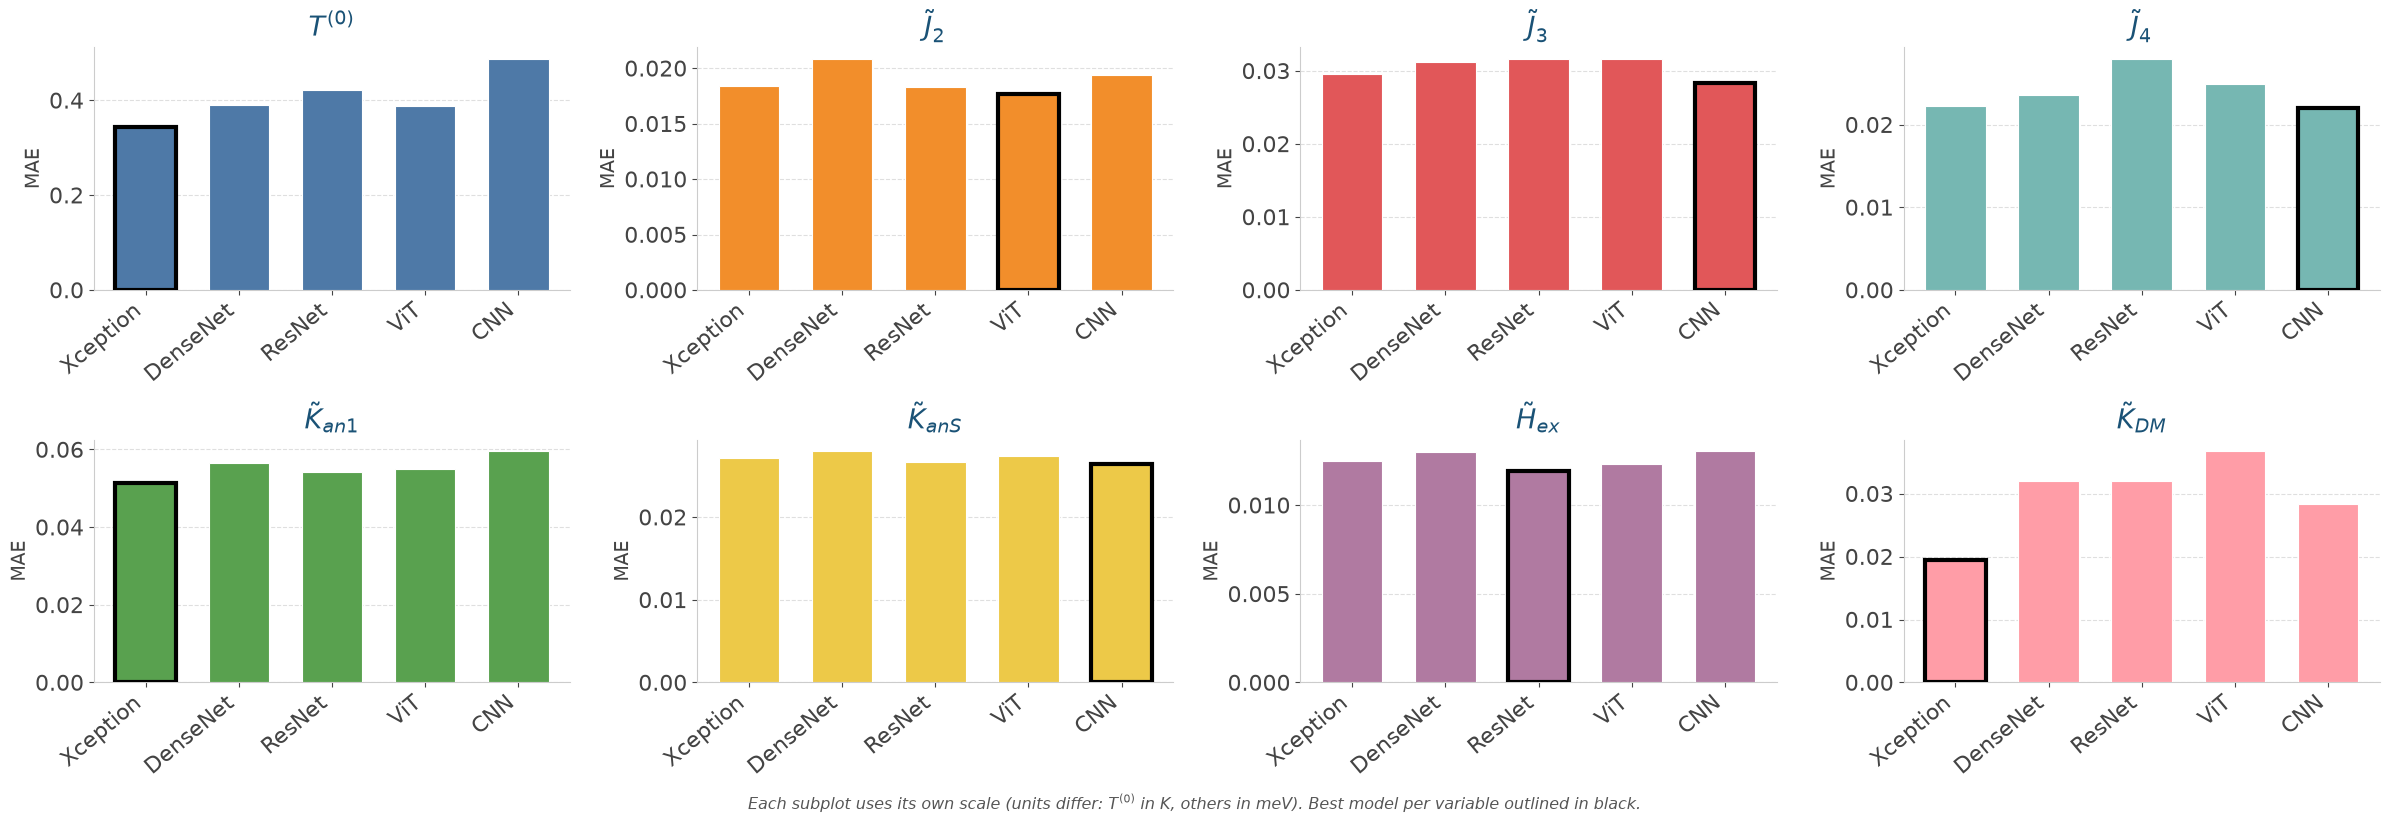

✅ Guardado en /workspace/Process/Images/model_comparison_mae.pdf


In [9]:
import numpy as np
import matplotlib.pyplot as plt

FONTSCALE = 1.5
FS_TITLE  = 13 * FONTSCALE
FS_LABEL  = 11 * FONTSCALE
FS_TICK   = 15 * FONTSCALE
FS_STATS  =  9 * FONTSCALE
c_line = "#1a5276"



var_colors = ["#4e79a7", "#f28e2b", "#e15759", "#76b7b2",
              "#59a14f", "#edc948", "#b07aa1", "#ff9da7"]
var_labels_plot = [r"$T^{(0)}$", r"$\tilde{J}_2$", r"$\tilde{J}_3$", r"$\tilde{J}_4$",
                   r"$\tilde{K}_{an1}$", r"$\tilde{K}_{anS}$", r"$\tilde{H}_{ex}$", r"$\tilde{K}_{DM}$"]

fig, axes = plt.subplots(2, 4, figsize=(24, 8), facecolor="white")
axes = axes.flatten()

x_models = np.arange(len(ok_models))

for v_i, (var_name, var_label) in enumerate(zip(param_names, var_labels_plot)):
    ax = axes[v_i]
    ax.set_facecolor("white")

    vals = [per_param_mae[m][v_i] for m in ok_models]
    bars = ax.bar(x_models, vals, width=0.65,
                  color=var_colors[v_i], edgecolor="white",
                  linewidth=0.8, zorder=3)

    # Resaltar el mejor modelo (menor MAE) — borde negro grueso
    best_i = int(np.argmin(vals))
    bars[best_i].set_edgecolor("#000000")
    bars[best_i].set_linewidth(3.0)
    bars[best_i].set_zorder(5)

    ax.set_xticks(x_models)
    ax.set_xticklabels(ok_models, fontsize=FS_TICK * 0.65,
                       rotation=40, ha="right")
    ax.set_title(var_label, fontsize=FS_TITLE, fontweight="bold", color=c_line, pad=8)
    ax.set_ylabel("MAE", color="#444444", fontsize=FS_LABEL * 0.85)
    ax.tick_params(colors="#444444", labelsize=FS_TICK * 0.7)
    ax.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#cccccc")
    ax.spines["bottom"].set_color("#cccccc")

fig.text(0.5, -0.02,
         r"Each subplot uses its own scale (units differ: $T^{(0)}$ in K, others in meV). "
         r"Best model per variable outlined in black.",
         ha="center", fontsize=FS_STATS * 0.85, color="#555555", style="italic")

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/model_comparison_mae.pdf", bbox_inches="tight", facecolor="white")
plt.show()
print(f"✅ Guardado en {OUT_DIR}/model_comparison_mae.pdf")




✅ Listo


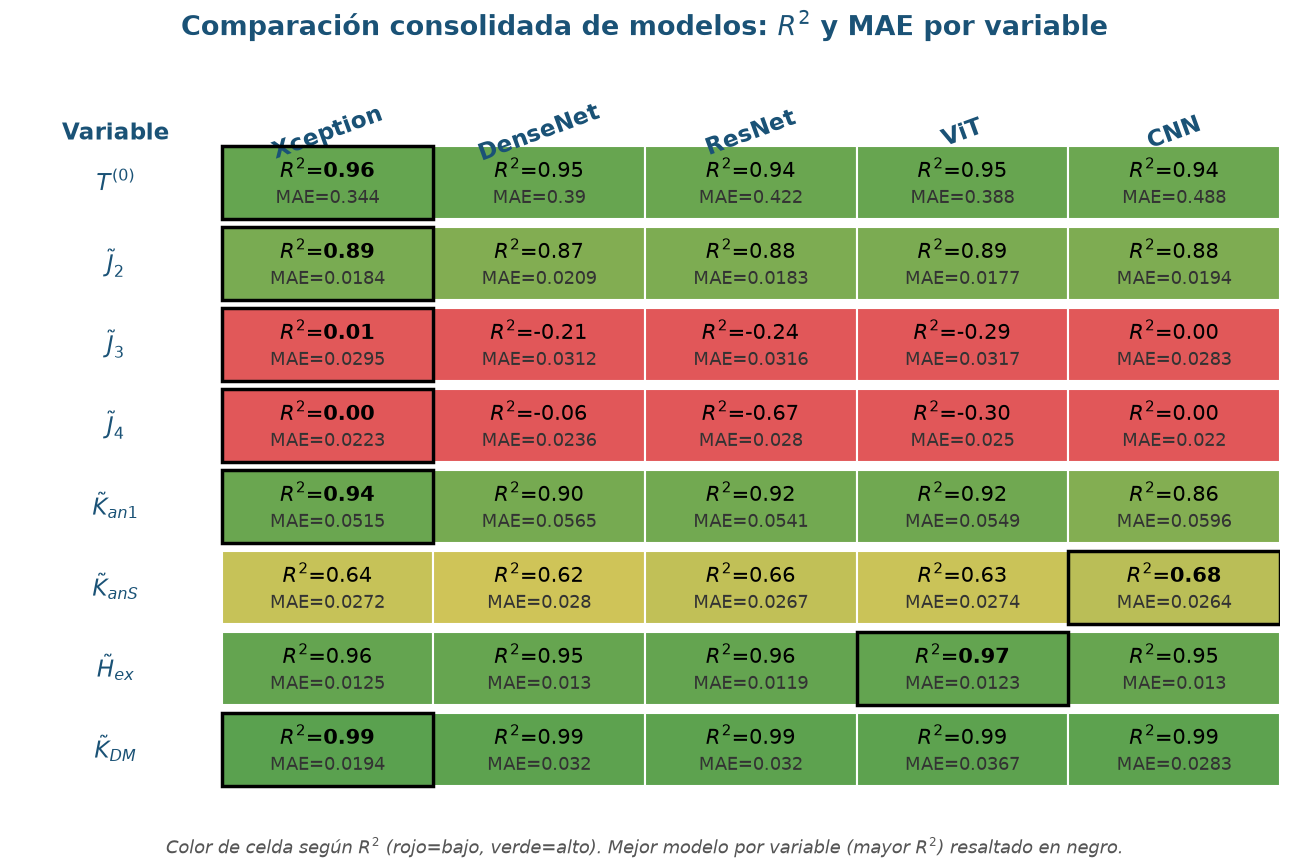

✅ Guardado en /workspace/Process/Images/model_comparison_table.pdf


In [10]:
!pip install umap-learn phate scikit-learn --quiet
print("✅ Listo")   


import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import LinearSegmentedColormap

FONTSCALE = 1.5
FS_TITLE  = 13 * FONTSCALE
FS_LABEL  = 11 * FONTSCALE
FS_CELL   = 10 * FONTSCALE
FS_HEADER = 11 * FONTSCALE
c_line = "#1a5276"

n_vars = len(param_names)
n_models = len(ok_models)

# Colormap para el heatmap de R² (rojo -> amarillo -> verde)
cmap = LinearSegmentedColormap.from_list(
    "r2cmap", ["#e15759", "#f2cf5b", "#59a14f"]
)

fig, ax = plt.subplots(figsize=(2.2 * n_models + 2, 0.9 * n_vars + 1.5),
                        facecolor="white")
ax.set_xlim(0, n_models + 1)
ax.set_ylim(0, n_vars + 1)
ax.axis("off")
ax.invert_yaxis()

# --- Encabezados de columnas (modelos) ---
for j, model in enumerate(ok_models):
    ax.text(j + 1.5, 0.4, model, ha="center", va="center",
             fontsize=FS_HEADER, fontweight="bold", color=c_line,
             rotation=20)

# --- Encabezado esquina ---
ax.text(0.5, 0.4, "Variable", ha="center", va="center",
         fontsize=FS_HEADER, fontweight="bold", color=c_line)

# --- Filas (variables) ---
for v_i, var_label in enumerate(var_labels_plot):
    y = v_i + 1

    # Nombre de variable
    ax.text(0.5, y, var_label, ha="center", va="center",
             fontsize=FS_LABEL, fontweight="bold", color=c_line)

    r2_row  = [per_param_r2[m][v_i]  for m in ok_models]
    mae_row = [per_param_mae[m][v_i] for m in ok_models]
    best_i = int(np.argmax(r2_row))  # mejor modelo según R²

    for j, model in enumerate(ok_models):
        x = j + 1
        r2  = r2_row[j]
        mae = mae_row[j]

        # Color de celda según R² (clip a [0,1] solo visual)
        r2_clip = np.clip(r2, 0, 1)
        color = cmap(r2_clip)

        rect = Rectangle((x, y - 0.45), 1, 0.9,
                          facecolor=color, edgecolor="white", linewidth=1.5,
                          zorder=2)
        ax.add_patch(rect)

        # Resaltar mejor modelo con borde negro grueso
        if j == best_i:
            rect_best = Rectangle((x, y - 0.45), 1, 0.9,
                                   facecolor="none", edgecolor="black",
                                   linewidth=2.5, zorder=4)
            ax.add_patch(rect_best)

        # Texto: R² arriba, MAE abajo
        ax.text(x + 0.5, y - 0.15, f"$R^2$={r2:.2f}",
                 ha="center", va="center", fontsize=FS_CELL,
                 fontweight="bold" if j == best_i else "normal",
                 color="black")
        ax.text(x + 0.5, y + 0.20, f"MAE={mae:.3g}",
                 ha="center", va="center", fontsize=FS_CELL * 0.85,
                 color="#333333")

fig.suptitle("Comparación consolidada de modelos: $R^2$ y MAE por variable",
             fontsize=FS_TITLE, fontweight="bold", color=c_line, y=0.98)
fig.text(0.5, 0.01,
         "Color de celda según $R^2$ (rojo=bajo, verde=alto). "
         "Mejor modelo por variable (mayor $R^2$) resaltado en negro.",
         ha="center", fontsize=FS_CELL * 0.85, color="#555555", style="italic")

plt.tight_layout(rect=[0, 0.02, 1, 0.95])
plt.savefig(f"{OUT_DIR}/model_comparison_table.pdf", bbox_inches="tight", facecolor="white")
plt.show()
print(f"✅ Guardado en {OUT_DIR}/model_comparison_table.pdf")

In [11]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
from tqdm import tqdm

BEST_PATH = f"{BASE}/modelo_xception_heteroscedastico_estructuras.keras"
best = tf.keras.models.load_model(BEST_PATH, compile=False)
print(f"Modelo cargado. input={best.input_shape}  output={best.output_shape}")
    
# Extractor de features: preferimos la representación densa compartida
# (entrada a la cabeza 'mu'); si no existe, usamos el último GlobalAveragePooling2D.
try:
    shared = best.get_layer('mu').input
    feat_model = Model(best.input, shared)
    print(f"✅ Features desde representación compartida (input de 'mu'): dim={shared.shape[-1]}")
except Exception:
    gaps = [l for l in best.layers if isinstance(l, tf.keras.layers.GlobalAveragePooling2D)]
    feat_model = Model(best.input, gaps[-1].output)
    print(f"✅ Features desde último GlobalAveragePooling2D: dim={gaps[-1].output.shape[-1]}")

Modelo cargado. input=(None, 224, 224, 3)  output=(None, 16)
✅ Features desde representación compartida (input de 'mu'): dim=2048


In [12]:
AUTOTUNE = tf.data.AUTOTUNE
BATCH = 128
            
def prep_224(img, yy):
    img = tf.image.resize(img, [224, 224])
    img = tf.image.grayscale_to_rgb(img)
    return img, yy

feat_ds = (tf.data.Dataset.from_tensor_slices((X_test, y_test_scaled))
           .map(prep_224, num_parallel_calls=AUTOTUNE)
           .batch(BATCH).prefetch(AUTOTUNE))

n_batches = int(np.ceil(len(X_test) / BATCH))
features, y_store = [], []
for bx, by in tqdm(feat_ds, total=n_batches, desc="Extrayendo features"):
    features.append(feat_model(bx, training=False).numpy())
    y_store.append(by.numpy())

features = np.concatenate(features)
y_scaled = np.concatenate(y_store)
y_real   = scaler.inverse_transform(y_scaled)   # valores físicos reales

print(f"\nFeatures: {features.shape}")

# Submuestreo para las proyecciones (UMAP/PHATE son lentos en ~25k)
MAX_SAMPLES = 8000
rng = np.random.default_rng(42)
sel = rng.choice(len(features), size=min(MAX_SAMPLES, len(features)), replace=False)
features_s = features[sel]
y_real_s   = y_real[sel]
print(f"Submuestra para proyección: {features_s.shape}")

Extrayendo features: 100%|██████████| 195/195 [00:40<00:00,  4.80it/s]


Features: (24922, 2048)
Submuestra para proyección: (8000, 2048)


In [13]:
from sklearn.decomposition import PCA
import umap
import phate

# PCA a 50 componentes (acelera y estabiliza ambas proyecciones)
pca = PCA(n_components=50, random_state=42)
features_pca = pca.fit_transform(features_s)
print(f"PCA: {features_pca.shape}  varianza explicada={pca.explained_variance_ratio_.sum():.3f}")

# --- UMAP ---
print("\n▶ UMAP...")
reducer_umap = umap.UMAP(n_components=2, n_neighbors=10, min_dist=0.4,
                         metric="cosine", random_state=42)
emb_umap = reducer_umap.fit_transform(features_pca)
print(f"✅ UMAP: {emb_umap.shape}")

# --- PHATE ---
print("\n▶ PHATE...")
reducer_phate = phate.PHATE(n_components=2, knn=10, decay=40,
                            n_jobs=-1, random_state=42, verbose=False)
emb_phate = reducer_phate.fit_transform(features_pca)
print(f"✅ PHATE: {emb_phate.shape}")

PCA: (8000, 50)  varianza explicada=0.997

▶ UMAP...
✅ UMAP: (8000, 2)

▶ PHATE...
    SGD-MDS may not have converged: stress changed by -1.3% in final iterations. Consider increasing n_iter or adjusting learning_rate.
✅ PHATE: (8000, 2)


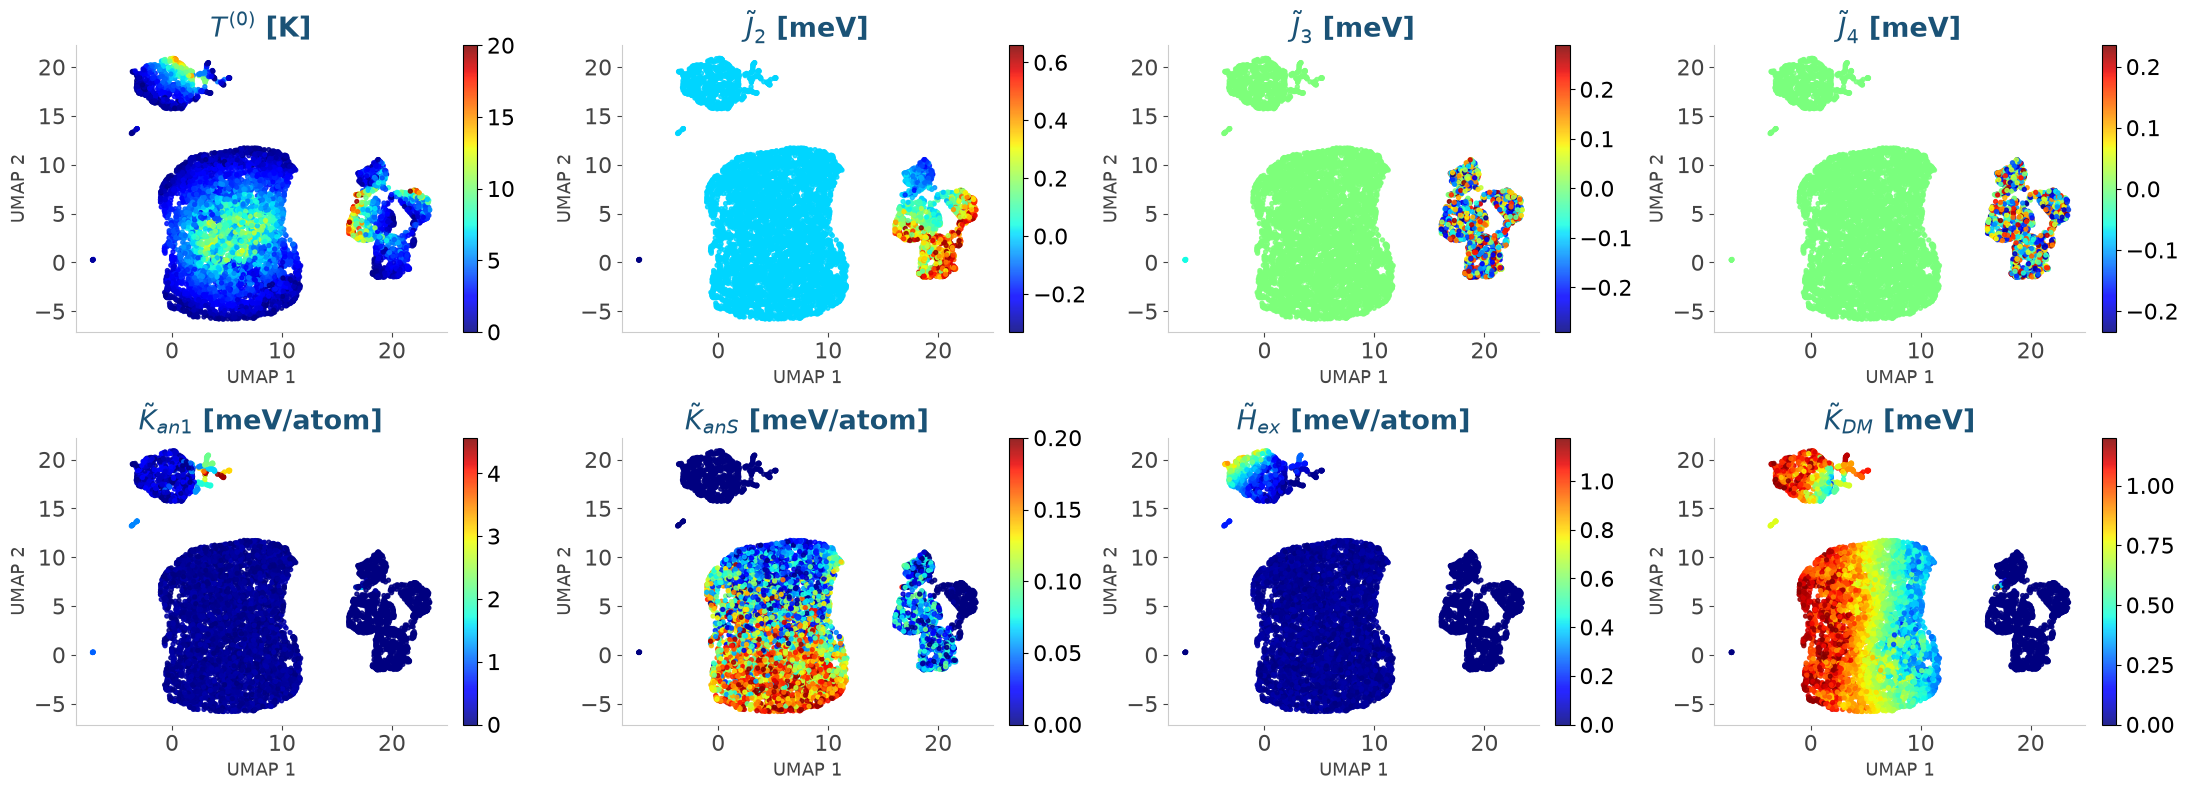

✅ Guardado en /workspace/Process/Images/latent_xception_umap.pdf


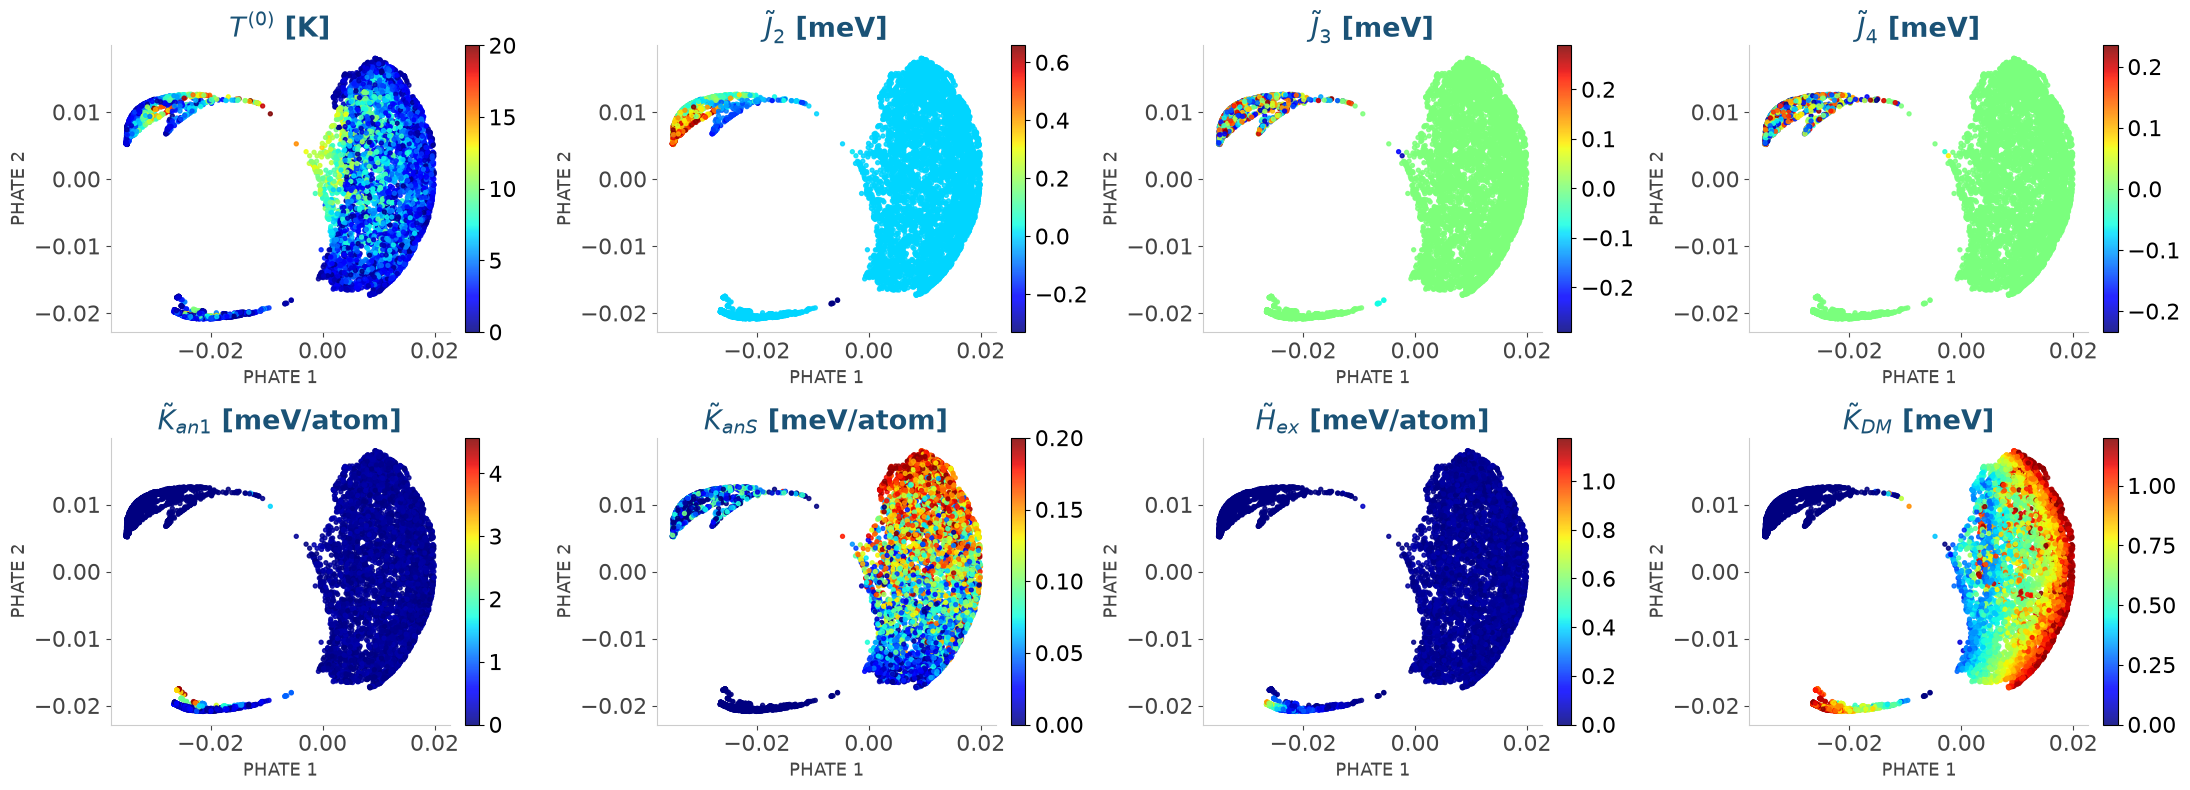

✅ Guardado en /workspace/Process/Images/latent_xception_phate.pdf


In [14]:
import matplotlib.pyplot as plt
import os

FONTSCALE = 1.5
FS_TITLE = 13 * FONTSCALE
FS_LABEL = 11 * FONTSCALE
FS_TICK  = 15 * FONTSCALE
c_line = "#1a5276"

param_labels_units = {
    "T": r"$T^{(0)}$ [K]", "Jex2": r"$\tilde{J}_2$ [meV]", "Jex3": r"$\tilde{J}_3$ [meV]",
    "Jex4": r"$\tilde{J}_4$ [meV]", "Kan1": r"$\tilde{K}_{an1}$ [meV/atom]",
    "KanS": r"$\tilde{K}_{anS}$ [meV/atom]", "Hex": r"$\tilde{H}_{ex}$ [meV/atom]",
    "KDM": r"$\tilde{K}_{DM}$ [meV]",
}

def plot_latent(embedding, y_vals, method_name, fname):
    fig, axes = plt.subplots(2, 4, figsize=(22, 8), facecolor="white")
    axes = axes.flatten()
    for i, name in enumerate(param_names):
        ax = axes[i]
        sc = ax.scatter(embedding[:, 0], embedding[:, 1], c=y_vals[:, i],
                        cmap="jet", s=8, rasterized=True, alpha=0.85)
        cb = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
        cb.ax.tick_params(labelsize=FS_TICK * 0.7)
        ax.set_title(param_labels_units[name], fontsize=FS_TITLE, fontweight="bold",
                     color=c_line, pad=6)
        ax.set_xlabel(f"{method_name} 1", fontsize=FS_LABEL * 0.8, color="#444444")
        ax.set_ylabel(f"{method_name} 2", fontsize=FS_LABEL * 0.8, color="#444444")
        ax.tick_params(labelsize=FS_TICK * 0.7, colors="#444444")
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_color("#cccccc")
        ax.spines["bottom"].set_color("#cccccc")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{fname}", bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"✅ Guardado en {OUT_DIR}/{fname}")

plot_latent(emb_umap,  y_real_s, "UMAP",  "latent_xception_umap.pdf")
plot_latent(emb_phate, y_real_s, "PHATE", "latent_xception_phate.pdf")

In [15]:
import umap
import phate

# Sin PCA: proyección directa sobre las features del modelo
print(f"Features directas: {features_s.shape}")

# --- UMAP directo ---
print("\n▶ UMAP (directo)...")
reducer_umap = umap.UMAP(n_components=2, n_neighbors=10, min_dist=0.4,
                         metric="cosine", random_state=42)
emb_umap = reducer_umap.fit_transform(features_s)
print(f"✅ UMAP: {emb_umap.shape}")

# --- PHATE directo ---
print("\n▶ PHATE (directo)...")
reducer_phate = phate.PHATE(n_components=2, knn=10, decay=40,
                            n_jobs=-1, random_state=42, verbose=False)
emb_phate = reducer_phate.fit_transform(features_s)
print(f"✅ PHATE: {emb_phate.shape}")

Features directas: (8000, 2048)

▶ UMAP (directo)...
✅ UMAP: (8000, 2)

▶ PHATE (directo)...
    SGD-MDS may not have converged: stress changed by -1.1% in final iterations. Consider increasing n_iter or adjusting learning_rate.
✅ PHATE: (8000, 2)


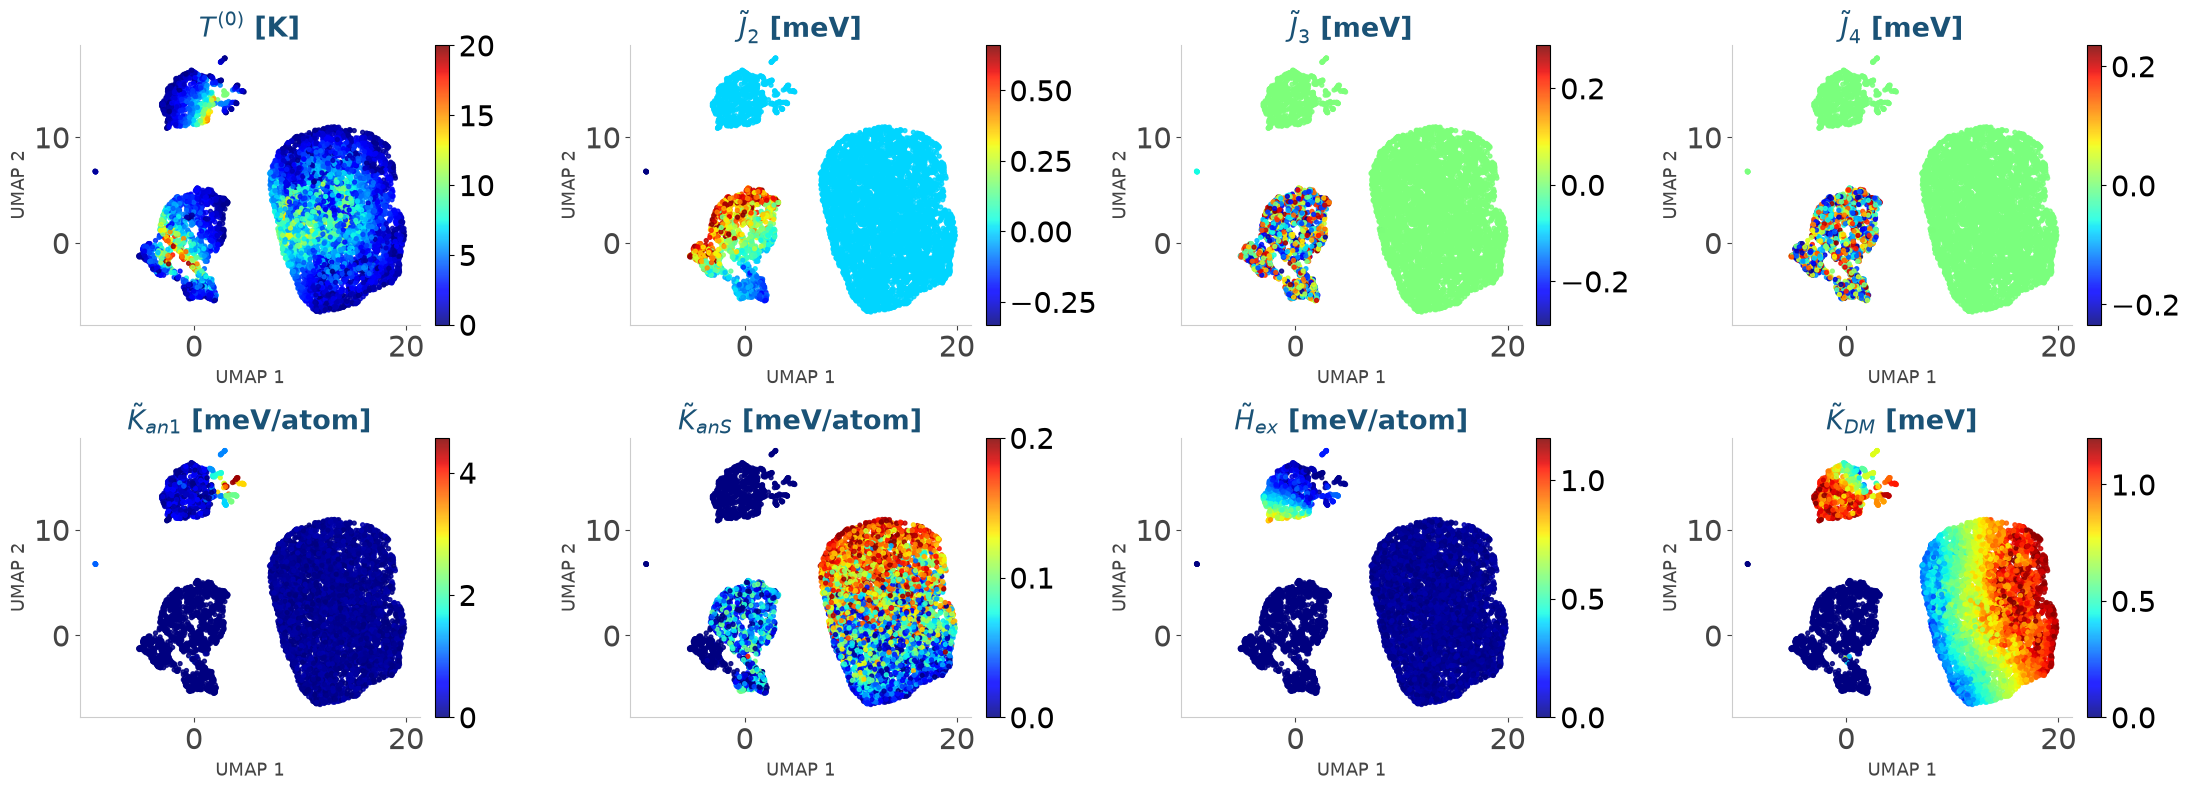

✅ Guardado en /workspace/Process/Images/latent_xception_umap.pdf


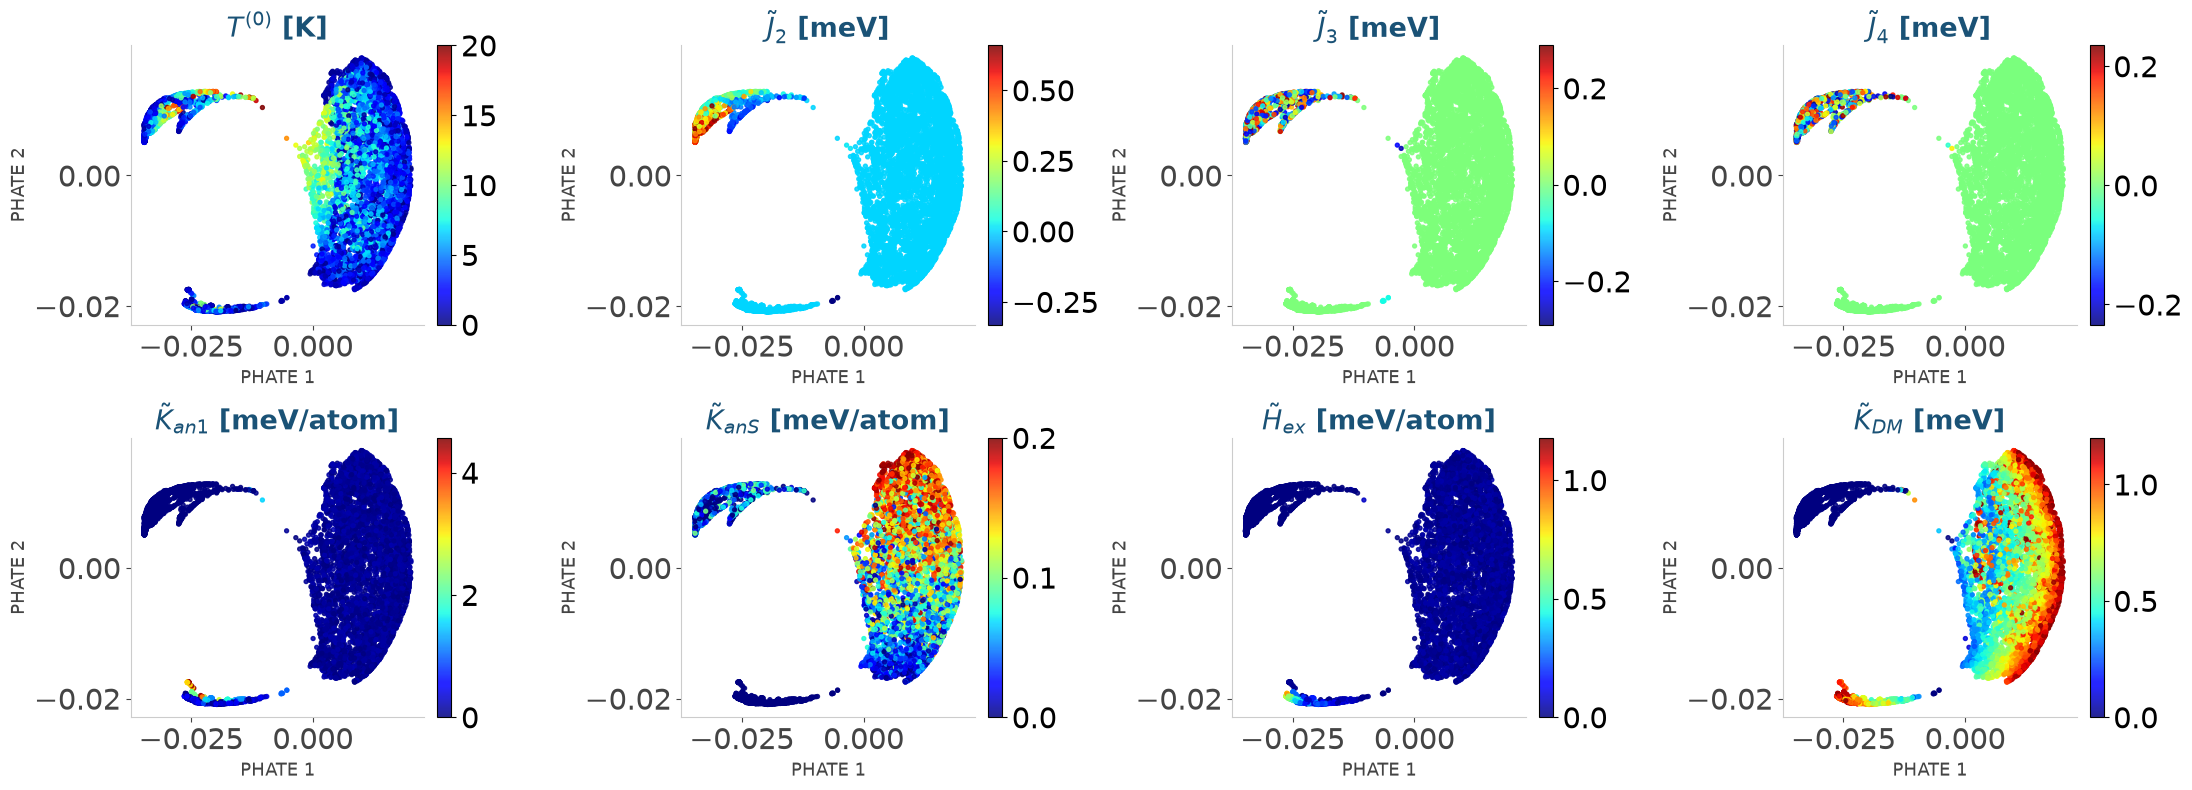

✅ Guardado en /workspace/Process/Images/latent_xception_phate.pdf


In [21]:
import matplotlib.pyplot as plt
import os



FONTSCALE = 1.5
FS_TITLE = 13 * FONTSCALE
FS_LABEL = 11 * FONTSCALE
FS_TICK  = 20 * FONTSCALE
c_line = "#1a5276"

param_labels_units = {
    "T": r"$T^{(0)}$ [K]", "Jex2": r"$\tilde{J}_2$ [meV]", "Jex3": r"$\tilde{J}_3$ [meV]",
    "Jex4": r"$\tilde{J}_4$ [meV]", "Kan1": r"$\tilde{K}_{an1}$ [meV/atom]",
    "KanS": r"$\tilde{K}_{anS}$ [meV/atom]", "Hex": r"$\tilde{H}_{ex}$ [meV/atom]",
    "KDM": r"$\tilde{K}_{DM}$ [meV]",
}

def plot_latent(embedding, y_vals, method_name, fname):
    fig, axes = plt.subplots(2, 4, figsize=(22, 8), facecolor="white")
    axes = axes.flatten()
    for i, name in enumerate(param_names):
        ax = axes[i]
        sc = ax.scatter(embedding[:, 0], embedding[:, 1], c=y_vals[:, i],
                        cmap="jet", s=8, rasterized=True, alpha=0.85)
        cb = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
        cb.ax.tick_params(labelsize=FS_TICK * 0.7)
        ax.set_title(param_labels_units[name], fontsize=FS_TITLE, fontweight="bold",
                     color=c_line, pad=6)
        ax.set_xlabel(f"{method_name} 1", fontsize=FS_LABEL * 0.8, color="#444444")
        ax.set_ylabel(f"{method_name} 2", fontsize=FS_LABEL * 0.8, color="#444444")
        ax.tick_params(labelsize=FS_TICK * 0.7, colors="#444444")
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_color("#cccccc")
        ax.spines["bottom"].set_color("#cccccc")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{fname}", bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"✅ Guardado en {OUT_DIR}/{fname}")
    
plot_latent(emb_umap,  y_real_s, "UMAP",  "latent_xception_umap.pdf")
plot_latent(emb_phate, y_real_s, "PHATE", "latent_xception_phate.pdf")

In [17]:
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import numpy as np
import os

FONTSCALE = 1.5
FS_TITLE = 13 * FONTSCALE
FS_LABEL = 11 * FONTSCALE
FS_TICK  = 10 * FONTSCALE
c_line = "#1a5276"
    
def plot_latent_with_images(embedding, images_norm, method_name, fname,
                            n_show=350, zoom=0.30, bg_param=None, y_vals=None,
                            bg_param_label=None):
    """Proyección latente con miniaturas de estados magnéticos embebidas."""
    fig, ax = plt.subplots(figsize=(15, 13), facecolor="white")
    ax.set_facecolor("white")

    # Scatter de fondo
    if bg_param is not None and y_vals is not None:
        sc = ax.scatter(embedding[:, 0], embedding[:, 1],
                        c=y_vals[:, bg_param], cmap="jet",
                        s=14, alpha=0.30, rasterized=True, zorder=1)
        cb = fig.colorbar(sc, ax=ax, fraction=0.035, pad=0.02)
        cb.set_label(bg_param_label, fontsize=FS_LABEL, color="#444444")
        cb.ax.tick_params(labelsize=FS_TICK * 0.8, colors="#444444")
    else:
        ax.scatter(embedding[:, 0], embedding[:, 1],
                   color="#c9d6e5", s=12, alpha=0.35,
                   rasterized=True, zorder=1)

    # Miniaturas embebidas
    np.random.seed(42)
    n_show = min(n_show, len(embedding))
    indices = np.random.choice(len(embedding), n_show, replace=False)
    for i in indices:
        x_pos, y_pos = embedding[i]
        imagebox = OffsetImage(images_norm[i], zoom=zoom, cmap="jet")
        ab = AnnotationBbox(imagebox, (x_pos, y_pos),
                            frameon=False, zorder=3, pad=0)
        ax.add_artist(ab)

    ax.set_xlabel(f"{method_name} 1", fontsize=FS_LABEL, color="#444444", labelpad=8)
    ax.set_ylabel(f"{method_name} 2", fontsize=FS_LABEL, color="#444444", labelpad=8)
    ax.set_title(f"Latent space of Xception ({method_name}) — magnetization textures",
                 fontsize=FS_TITLE, fontweight="bold", color=c_line, pad=12)
    ax.tick_params(labelsize=FS_TICK * 0.8, colors="#444444")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#cccccc")
    ax.spines["bottom"].set_color("#cccccc")

    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{fname}", bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"✅ Guardado en {OUT_DIR}/{fname}")

images_s_norm: (8000, 39, 39)  |  emb_umap: 8000  (deben coincidir)


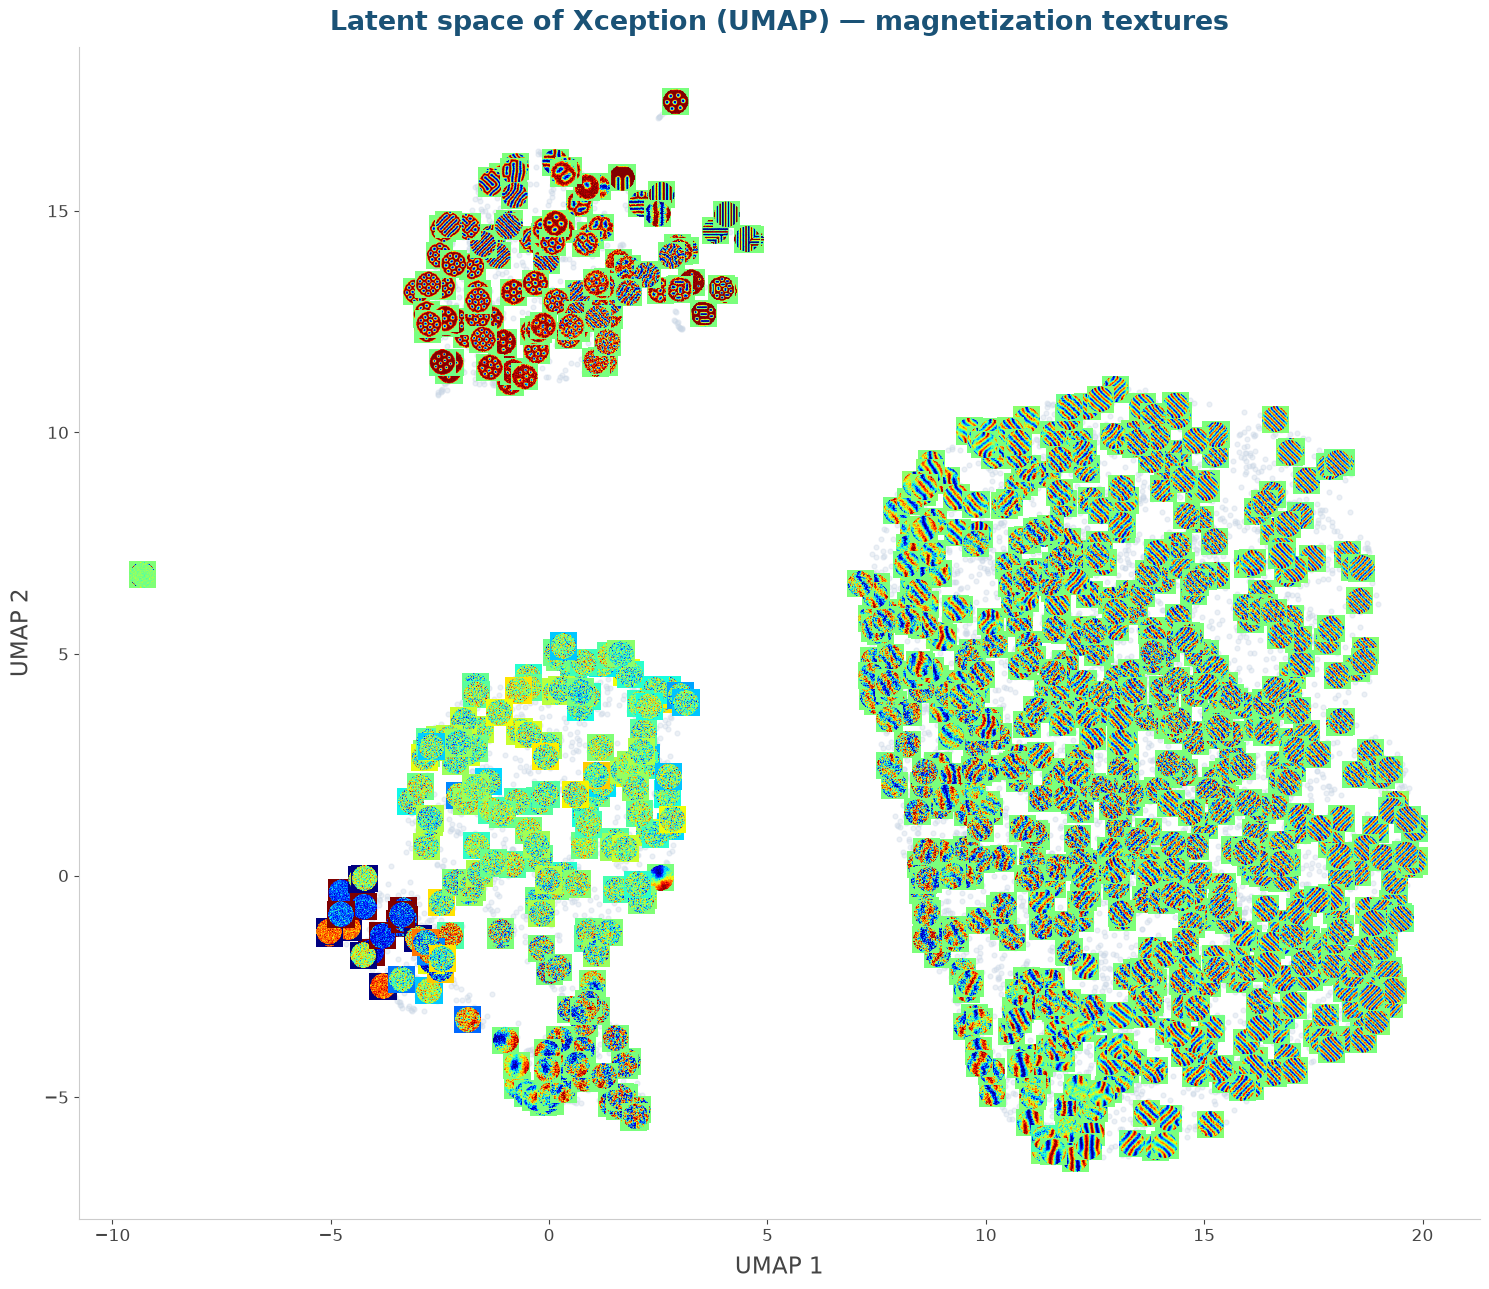

✅ Guardado en /workspace/Process/Images/latent_umap_states.pdf


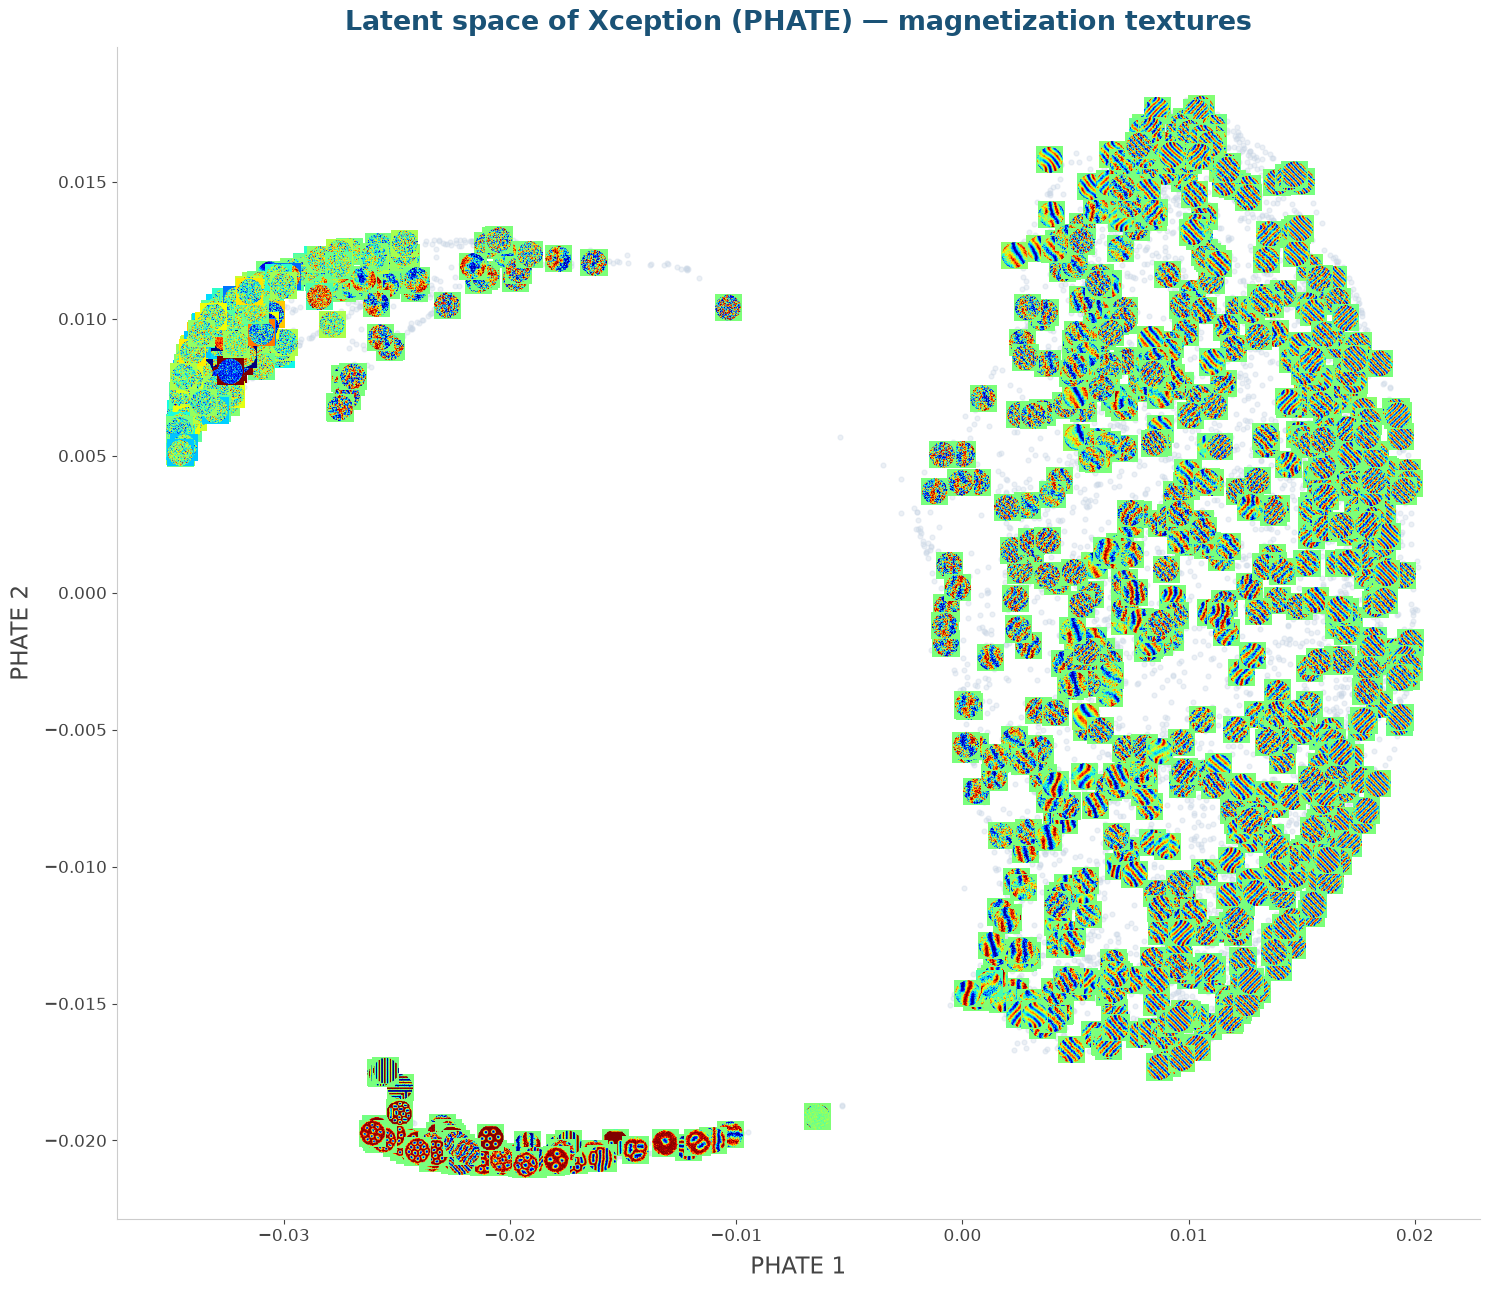

✅ Guardado en /workspace/Process/Images/latent_phate_states.pdf


In [18]:

# Miniaturas normalizadas del MISMO subconjunto 'sel' usado en features_s
images_s = X_test[sel][:, :, :, 0]                       # canal único -> (n, 39, 39)
gmin, gmax = images_s.min(), images_s.max()
images_s_norm = (images_s - gmin) / (gmax - gmin + 1e-8)



print(f"images_s_norm: {images_s_norm.shape}  |  emb_umap: {emb_umap.shape[0]}  (deben coincidir)")
plot_latent_with_images(emb_umap,  images_s_norm, "UMAP",
                        "latent_umap_states.pdf", n_show=1000, zoom=0.50)

plot_latent_with_images(emb_phate, images_s_norm, "PHATE",
                        "latent_phate_states.pdf", n_show=1000, zoom=0.50)

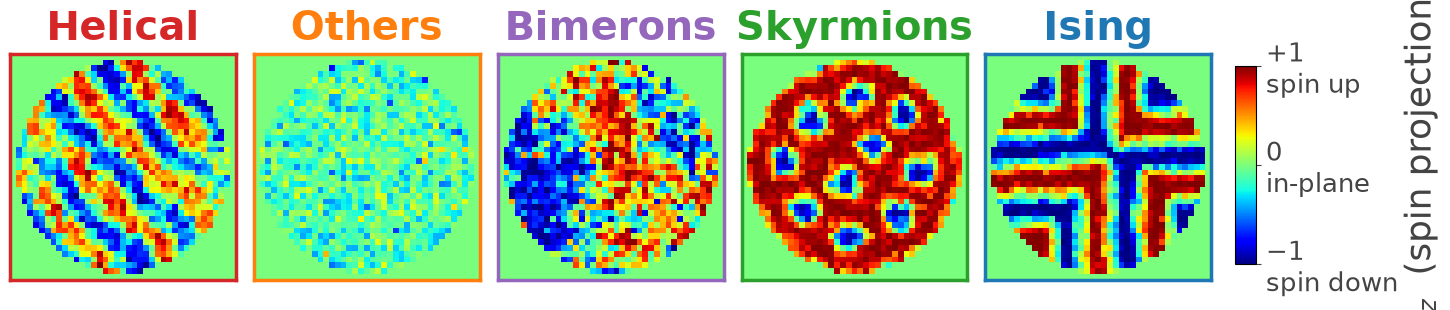

✅ structures_representatives_horizontal.pdf


In [23]:
import numpy as np
import matplotlib.pyplot as plt
import os

# ══════════════════════════════════════════════════════════
# Ejemplos por estructura — layout HORIZONTAL (2 representantes)
# ══════════════════════════════════════════════════════════
DATASET_PATH = "/workspace/Preprocess/latent_space_outputs/dataset_final_estructuras.npz"
OUT_DIR = "/workspace/Process/Images"
os.makedirs(OUT_DIR, exist_ok=True)

FONTSCALE = 2.6
FS_TITLE = 13 * FONTSCALE; FS_LABEL = 11 * FONTSCALE
c_line = "#1a5276"

structure_colors = {"helical": "#d62728", "Others": "#ff7f0e", "Bimerones": "#9467bd",
                    "Skyrmiones": "#2ca02c", "Ising": "#1f77b4"}
structure_labels = {"helical": "Helical", "Others": "Others", "Bimerones": "Bimerons",
                    "Skyrmiones": "Skyrmions", "Ising": "Ising"}

data = np.load(DATASET_PATH, allow_pickle=True)
X = data["img"].astype(np.float32).squeeze()          # (N,39,39)
params = data["params"].astype(np.float64)
labels = np.array([str(s) for s in data["label_names"]])

structures = [s for s in ["helical", "Others", "Bimerones", "Skyrmiones", "Ising"]
              if (labels == s).sum() > 0]

N_REPS = 1
rng = np.random.default_rng(42)

# ── 2 representantes por estructura: el más típico (cercano a la media
#    de parámetros) + uno del percentil 30 para mostrar variedad
reps = {}
for s in structures:
    idx_s = np.where(labels == s)[0]
    mean_p = params[idx_s].mean(axis=0)
    d = np.linalg.norm(params[idx_s] - mean_p, axis=1)
    orden = idx_s[np.argsort(d)]
    reps[s] = [orden[0], orden[int(len(orden) * 0.30)]]

vmin, vmax = X.min(), X.max()

# ── Figura: estructuras en columnas (horizontal), 2 filas de representantes ──
n_str = len(structures)
fig, axes = plt.subplots(N_REPS, n_str, figsize=(3.1 * n_str, 3.1 * N_REPS),
                         facecolor="white",
                         gridspec_kw={"hspace": 0.08, "wspace": 0.08})
if N_REPS == 1:
    axes = axes[np.newaxis, :]

for ci, s in enumerate(structures):
    for ri in range(N_REPS):
        ax = axes[ri, ci]
        ax.imshow(X[reps[s][ri]], cmap="jet", vmin=vmin, vmax=vmax,
                  interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_edgecolor(structure_colors[s]); sp.set_linewidth(2.5); sp.set_visible(True)
    axes[0, ci].set_title(structure_labels[s], fontsize=FS_LABEL,
                          fontweight="bold", color=structure_colors[s], pad=10)

# ── Colorbar explicativa: proyección del espín en z ──
fig.subplots_adjust(right=0.90)
cbar_ax = fig.add_axes([0.915, 0.18, 0.014, 0.64])
sm = plt.cm.ScalarMappable(cmap="jet", norm=plt.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])
cb = fig.colorbar(sm, cax=cbar_ax)
cb.set_label(r"$m_z$  (spin projection)", fontsize=FS_LABEL * 0.9, color="#444444")
cb.set_ticks([-1, 0, 1])
cb.set_ticklabels(["−1\nspin down", "0\nin-plane", "+1\nspin up"])
cb.ax.tick_params(labelsize=FS_LABEL * 0.65, colors="#444444")

plt.savefig(f"{OUT_DIR}/structures_representatives_horizontal.pdf",
            bbox_inches="tight", facecolor="white")
plt.show()
print("✅ structures_representatives_horizontal.pdf")

In [24]:
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score
    
# Necesitamos las predicciones del mejor modelo sobre el test set,
# junto con la etiqueta de estructura de cada muestra de test.

# 1) Etiquetas de estructura alineadas con el MISMO split del test
_d = np.load(DATASET_PATH, allow_pickle=True)
label_all = np.array([str(s) for s in _d['label_names']])

# Reproducir el split para recuperar las etiquetas de test (mismo seed/orden)
from sklearn.model_selection import train_test_split
idx_all = np.arange(len(label_all))
idx_tr, idx_te = train_test_split(idx_all, test_size=0.15, random_state=SEED)
label_test = label_all[idx_te]   # estructura de cada muestra de test

print(f"label_test: {label_test.shape}  (debe = {y_true.shape[0]})")

# 2) Predicciones del mejor modelo (Xception-Hetero) sobre test
best = tf.keras.models.load_model(
    f"{BASE}/modelo_xception_heteroscedastico_estructuras.keras", compile=False)

def prep_224(img, yy):
    img = tf.image.resize(img, [224, 224])
    img = tf.image.grayscale_to_rgb(img)
    return img, yy

test_ds = (tf.data.Dataset.from_tensor_slices((X_test, y_test_scaled))
           .map(prep_224, num_parallel_calls=tf.data.AUTOTUNE)
           .batch(128).prefetch(tf.data.AUTOTUNE))

y_pred_full = best.predict(test_ds, verbose=0)
y_pred_scaled = y_pred_full[:, :8]   # solo μ (heteroscedástico)
y_pred_best = scaler.inverse_transform(y_pred_scaled)
y_true_best = y_test.copy()

# 3) R² por estructura × variable
var_names = [r"$T^{(0)}$", r"$\tilde{J}_2$", r"$\tilde{J}_3$", r"$\tilde{J}_4$",
             r"$\tilde{K}_{an1}$", r"$\tilde{K}_{anS}$", r"$\tilde{H}_{ex}$", r"$\tilde{K}_{DM}$"]

structures = ["helical", "Others", "Bimerones", "Skyrmiones", "Ising"]
structures = [s for s in structures if (label_test == s).sum() > 0]

VAR_THRESHOLD = 1e-4
rows = []
for structure in structures:
    m = (label_test == structure)
    if m.sum() == 0:
        continue
    for v_i, var_name in enumerate(var_names):
        yt = y_true_best[m, v_i]
        yp = y_pred_best[m, v_i]
        r2 = np.nan if yt.var() < VAR_THRESHOLD else r2_score(yt, yp)
        rows.append({"Structure": structure, "Variable": var_name, "R²": r2})

var_struct_df = pd.DataFrame(rows)
print(var_struct_df.pivot(index="Structure", columns="Variable", values="R²").round(3).to_string())




label_test: (24922,)  (debe = 24922)
Variable    $T^{(0)}$  $\tilde{H}_{ex}$  $\tilde{J}_2$  $\tilde{J}_3$  $\tilde{J}_4$  $\tilde{K}_{DM}$  $\tilde{K}_{an1}$  $\tilde{K}_{anS}$
Structure                                                                                                                                   
Bimerones       0.826             0.535          0.620          0.027          0.000             0.734              0.149              0.344
Ising           0.990             0.934            NaN            NaN            NaN             0.964              0.979                NaN
Others          0.877               NaN          0.659          0.009         -0.003             0.986              0.922              0.425
Skyrmiones      0.994             0.974          0.963            NaN            NaN             0.975              0.940                NaN
helical         0.991             0.829          0.758            NaN            NaN             0.990              0

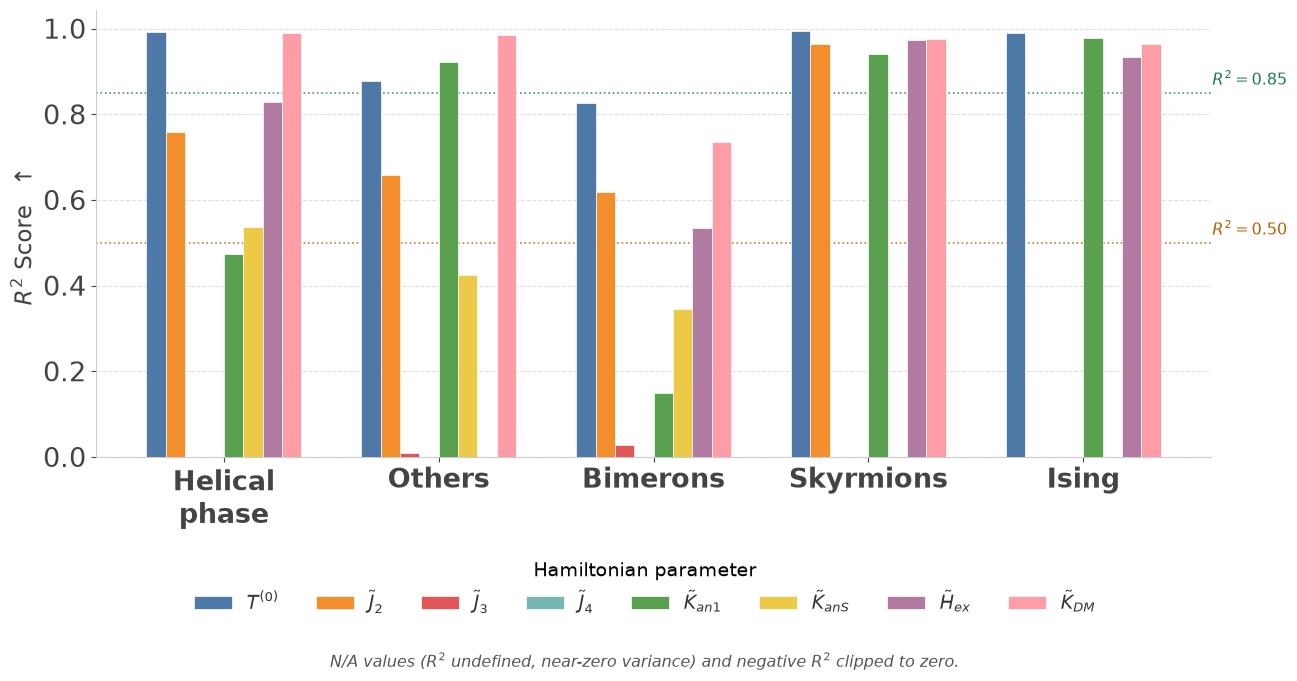

✅ Guardado en /workspace/Process/Images/metrics_by_structure_r2.pdf


In [25]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

FONTSCALE = 1.5
FS_TITLE  = 13 * FONTSCALE
FS_LABEL  = 11 * FONTSCALE
FS_TICK   = 15 * FONTSCALE
FS_STATS  =  9 * FONTSCALE
FS_LEGEND =  9 * FONTSCALE
c_line = "#1a5276"

var_colors = ["#4e79a7", "#f28e2b", "#e15759", "#76b7b2",
              "#59a14f", "#edc948", "#b07aa1", "#ff9da7"]

structure_colors = {
    "helical": "#d62728", "Others": "#ff7f0e", "Bimerones": "#9467bd",
    "Skyrmiones": "#2ca02c", "Ising": "#1f77b4",
}
structure_labels_short = {
    "helical": "Helical\nphase", "Others": "Others", "Bimerones": "Bimerons",
    "Skyrmiones": "Skyrmions", "Ising": "Ising",
}

# ══════════════════════════════════════════════════════════
# FIGURA — solo R², leyenda abajo
# ══════════════════════════════════════════════════════════
n_vars_pl = len(var_names)
bar_w     = 0.09
x_structs = np.arange(len(structures))

fig, ax = plt.subplots(figsize=(13, 6), facecolor="white")
ax.set_facecolor("white")

for v_i, var_name in enumerate(var_names):
    offset = (v_i - n_vars_pl / 2 + 0.5) * bar_w
    vals = []
    for structure in structures:
        row = var_struct_df.loc[
            (var_struct_df["Structure"] == structure) &
            (var_struct_df["Variable"]  == var_name), "R²"]
        val = row.values[0] if len(row) > 0 else np.nan
        vals.append(max(val, 0.0) if not np.isnan(val) else 0.0)
    ax.bar(x_structs + offset, vals, width=bar_w, label=var_name,
           color=var_colors[v_i], edgecolor="white", linewidth=0.5, zorder=3)

ax.axhline(0.85, color="#1a7a4a", linewidth=1.2, linestyle=":", alpha=0.8)
ax.axhline(0.50, color="#b85c00", linewidth=1.2, linestyle=":", alpha=0.8)
ax.text(len(structures) - 0.05, 0.86, r"$R^2=0.85$", fontsize=FS_STATS * 0.85,
        color="#1a7a4a", va="bottom", ha="right")
ax.text(len(structures) - 0.05, 0.51, r"$R^2=0.50$", fontsize=FS_STATS * 0.85,
        color="#b85c00", va="bottom", ha="right")

ax.set_xticks(x_structs)
ax.set_xticklabels([structure_labels_short[s] for s in structures],
                   fontsize=FS_TICK * 0.90, ha="center")
for tick, struct in zip(ax.get_xticklabels(), structures):
    tick.set_color(structure_colors[struct])
    tick.set_fontweight("bold")

ax.set_ylabel(r"$R^2$ Score  $\uparrow$", color="#444444", fontsize=FS_LABEL)
ax.tick_params(colors="#444444", labelsize=FS_TICK * 0.85)
ax.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
ax.set_ylim(bottom=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#cccccc")
ax.spines["bottom"].set_color("#cccccc")

var_handles = [
    mpatches.Patch(facecolor=var_colors[v_i], edgecolor="white",
                   linewidth=0.5, label=var_name)
    for v_i, var_name in enumerate(var_names)
]
fig.legend(handles=var_handles, loc="lower center", ncol=len(var_names),
           fontsize=FS_LEGEND, frameon=False, bbox_to_anchor=(0.5, -0.06),
           labelcolor="#333333", title="Hamiltonian parameter",
           title_fontsize=FS_LEGEND)

fig.text(0.5, -0.12,
         r"N/A values ($R^2$ undefined, near-zero variance) "
         r"and negative $R^2$ clipped to zero.",
         ha="center", fontsize=FS_STATS * 0.85, color="#555555", style="italic")


plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.savefig(f"{OUT_DIR}/metrics_by_structure_r2.pdf",
            bbox_inches="tight", facecolor="white")
plt.show()




print(f"✅ Guardado en {OUT_DIR}/metrics_by_structure_r2.pdf")

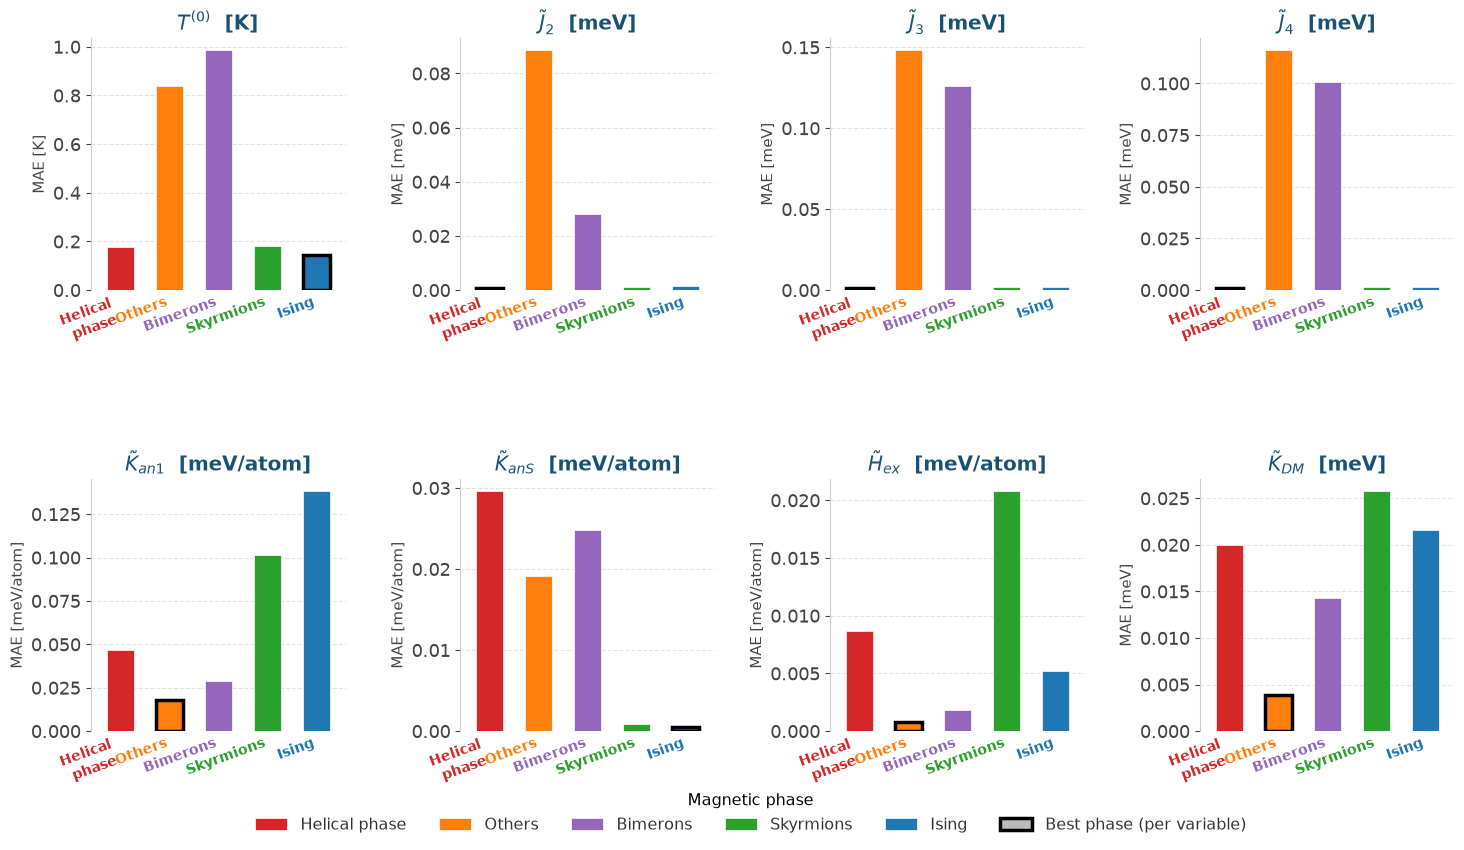

✅ Guardado en /workspace/Process/Images/metrics_by_structure_mae_grid.pdf


In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.metrics import mean_absolute_error

# ══════════════════════════════════════════════════════════
# ESCALA DE FUENTES
# ══════════════════════════════════════════════════════════
FONTSCALE   = 1.3
FS_SUPTITLE = 13 * FONTSCALE
FS_TITLE    = 11 * FONTSCALE
FS_LABEL    = 10 * FONTSCALE
FS_TICK     =  10 * FONTSCALE
FS_LEGEND   =  9 * FONTSCALE
c_line      = "#1a5276"

# ══════════════════════════════════════════════════════════
# NOMENCLATURA — con unidades físicas (orden del dataset)
# ══════════════════════════════════════════════════════════
variables = {
    r"$T^{(0)}$":         (0, "K"),
    r"$\tilde{J}_2$":     (1, "meV"),
    r"$\tilde{J}_3$":     (2, "meV"),
    r"$\tilde{J}_4$":     (3, "meV"),
    r"$\tilde{K}_{an1}$": (4, "meV/atom"),
    r"$\tilde{K}_{anS}$": (5, "meV/atom"),
    r"$\tilde{H}_{ex}$":  (6, "meV/atom"),
    r"$\tilde{K}_{DM}$":  (7, "meV"),
}





# ══════════════════════════════════════════════════════════
# ESTRUCTURAS (tus etiquetas reales)
# ══════════════════════════════════════════════════════════
structures = ["helical", "Others", "Bimerones", "Skyrmiones", "Ising"]
structures = [s for s in structures if (label_test == s).sum() > 0]

structure_colors = {
    "helical": "#d62728", "Others": "#ff7f0e", "Bimerones": "#9467bd",
    "Skyrmiones": "#2ca02c", "Ising": "#1f77b4",
}
structure_labels_short = {
    "helical": "Helical\nphase", "Others": "Others", "Bimerones": "Bimerons",
    "Skyrmiones": "Skyrmions", "Ising": "Ising",
}

# ══════════════════════════════════════════════════════════
# MAE POR ESTRUCTURA × VARIABLE (escala original)
# ══════════════════════════════════════════════════════════
rows_var = []
for structure in structures:
    mask = (label_test == structure)
    if mask.sum() == 0:
        continue
    for var_name, (idx, unit) in variables.items():
        mae = mean_absolute_error(y_true_best[mask, idx], y_pred_best[mask, idx])
        rows_var.append({"Structure": structure, "Variable": var_name,
                         "Unit": unit, "MAE": mae})

var_struct_df = pd.DataFrame(rows_var)

# ══════════════════════════════════════════════════════════
# FIGURA — grilla 4×2, un subplot por variable (escala propia)
# ══════════════════════════════════════════════════════════
NCOLS, NROWS = 4, 2
n_structs    = len(structures)
bar_w        = 0.55
x_base       = np.arange(n_structs)

fig, axes = plt.subplots(
    NROWS, NCOLS,
    figsize=(NCOLS * 4.4, NROWS * 4.5),
    facecolor="white",
    gridspec_kw={"hspace": 0.75, "wspace": 0.45},
)
axes = axes.flatten()

for ax_i, (var_name, (idx, unit)) in enumerate(variables.items()):
    ax = axes[ax_i]
    ax.set_facecolor("white")

    sub = var_struct_df[var_struct_df["Variable"] == var_name]
    vals_all = {
        s: sub[sub["Structure"] == s]["MAE"].values[0]
        for s in structures if len(sub[sub["Structure"] == s]) > 0
    }
    best_struct = min(vals_all, key=vals_all.get)   # menor MAE = mejor

    for s_i, structure in enumerate(structures):
        v  = vals_all.get(structure, 0.0)
        ec = "#000000" if structure == best_struct else "white"
        ew = 2.5       if structure == best_struct else 0.5
        ax.bar(s_i, v, width=bar_w, color=structure_colors[structure],
               edgecolor=ec, linewidth=ew, zorder=3)

    ax.set_xticks(x_base)
    ax.set_xticklabels([structure_labels_short[s] for s in structures],
                       fontsize=FS_TICK * 0.80, fontweight="bold",
                       rotation=20, ha="right")
    for tick, struct in zip(ax.get_xticklabels(), structures):
        tick.set_color(structure_colors[struct])

    ax.set_title(f"{var_name}  [{unit}]", fontsize=FS_TITLE, fontweight="bold",
                 color=c_line, pad=6)
    ax.set_ylabel(f"MAE [{unit}]", color="#444444", fontsize=FS_LABEL * 0.85)
    ax.tick_params(axis="y", colors="#444444", labelsize=FS_TICK)
    ax.tick_params(axis="x", length=0)
    ax.grid(axis="y", linestyle="--", alpha=0.35, zorder=0)
    ax.set_xlim(-0.6, n_structs - 0.4)
    ax.set_ylim(bottom=0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#cccccc")
    ax.spines["bottom"].set_visible(False)

# ── leyenda global ────────────────────────────────────────
struct_handles = [
    mpatches.Patch(facecolor=structure_colors[s], edgecolor="white",
                   linewidth=0.5, label=structure_labels_short[s].replace("\n", " "))
    for s in structures
]
best_handle = mpatches.Patch(facecolor="#bbbbbb", edgecolor="#000000",
                             linewidth=2.5, label="Best phase (per variable)")
fig.legend(handles=struct_handles + [best_handle], loc="lower center",
           ncol=len(structures) + 1, fontsize=FS_LEGEND, frameon=False,
           bbox_to_anchor=(0.5, -0.02), labelcolor="#333333",
           title="Magnetic phase", title_fontsize=FS_LEGEND)
plt.savefig(f"{OUT_DIR}/metrics_by_structure_mae_grid.pdf",
            bbox_inches="tight", facecolor="white")
plt.show()
print(f"✅ Guardado en {OUT_DIR}/metrics_by_structure_mae_grid.pdf")

label_test: (24922,)  (debe = 24922)
Variable    $T^{(0)}$  $\tilde{H}_{ex}$  $\tilde{J}_2$  $\tilde{J}_3$  $\tilde{J}_4$  $\tilde{K}_{DM}$  $\tilde{K}_{an1}$  $\tilde{K}_{anS}$
Structure                                                                                                                                   
Bimerones       0.826             0.535          0.620          0.027          0.000             0.734              0.149              0.344
Ising           0.990             0.934            NaN            NaN            NaN             0.964              0.979                NaN
Others          0.877               NaN          0.659          0.009         -0.003             0.986              0.922              0.425
Skyrmiones      0.994             0.974          0.963            NaN            NaN             0.975              0.940                NaN
helical         0.991             0.829          0.758            NaN            NaN             0.990              0

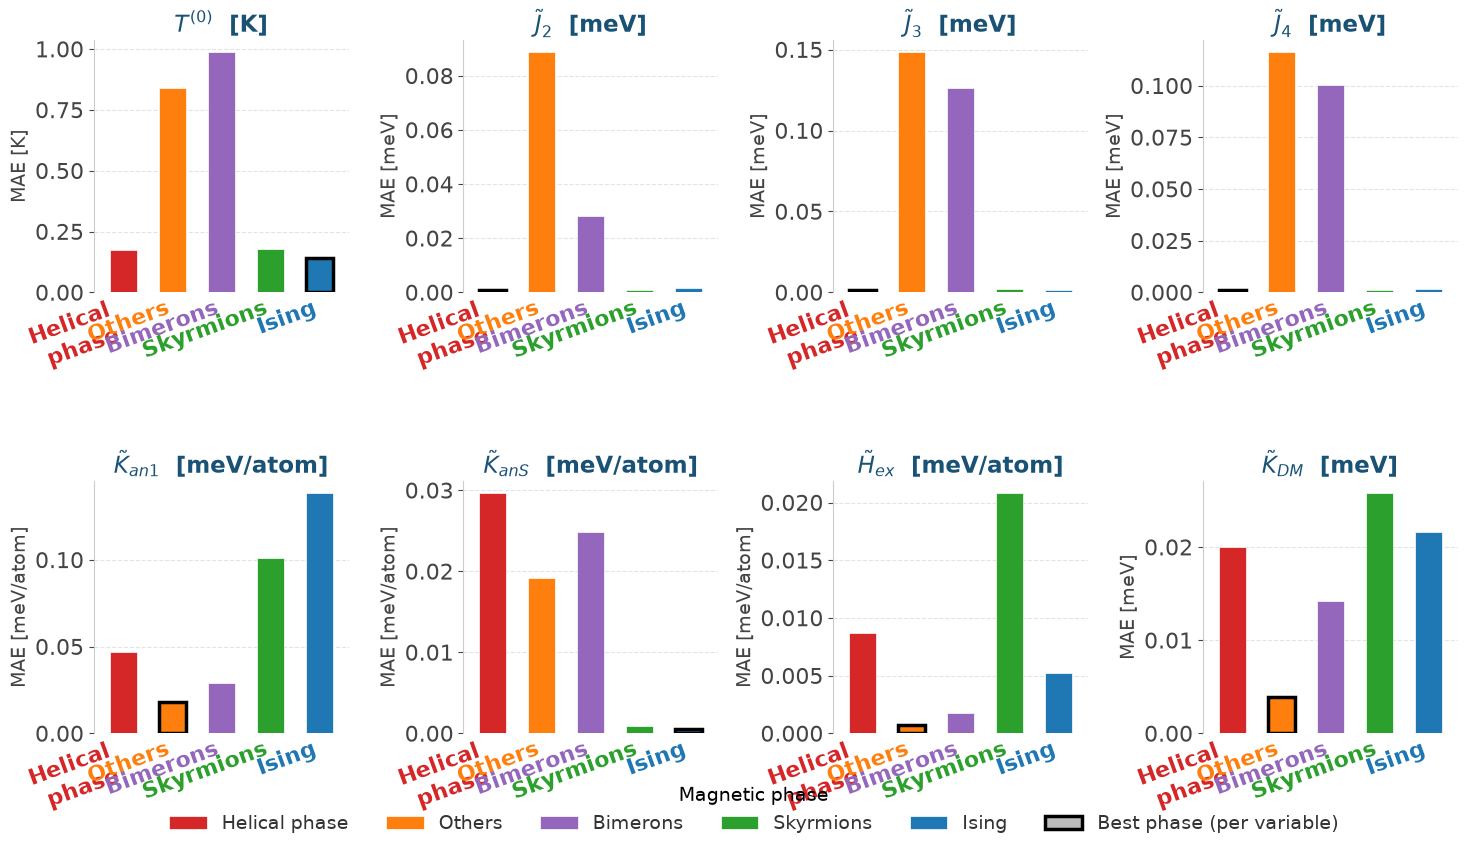

✅ Guardado en /workspace/Process/Images/metrics_by_structure_mae_grid.pdf


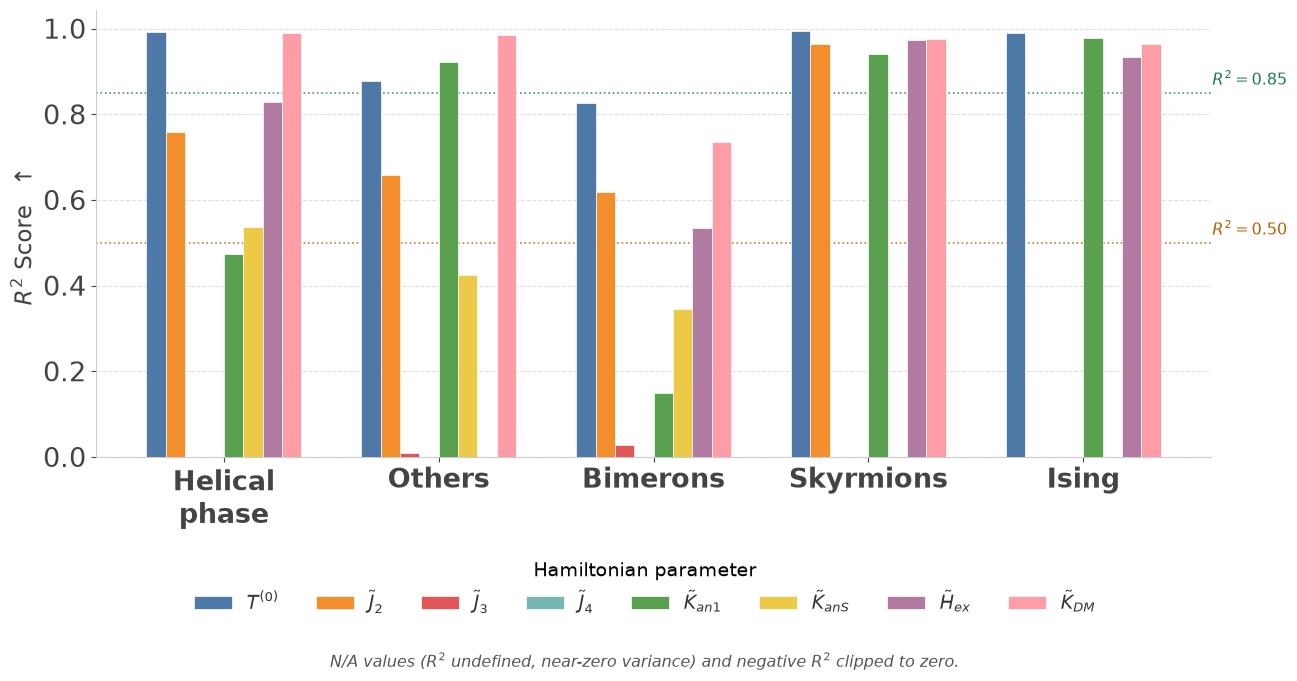

✅ Guardado en /workspace/Process/Images/metrics_by_structure_r2.pdf


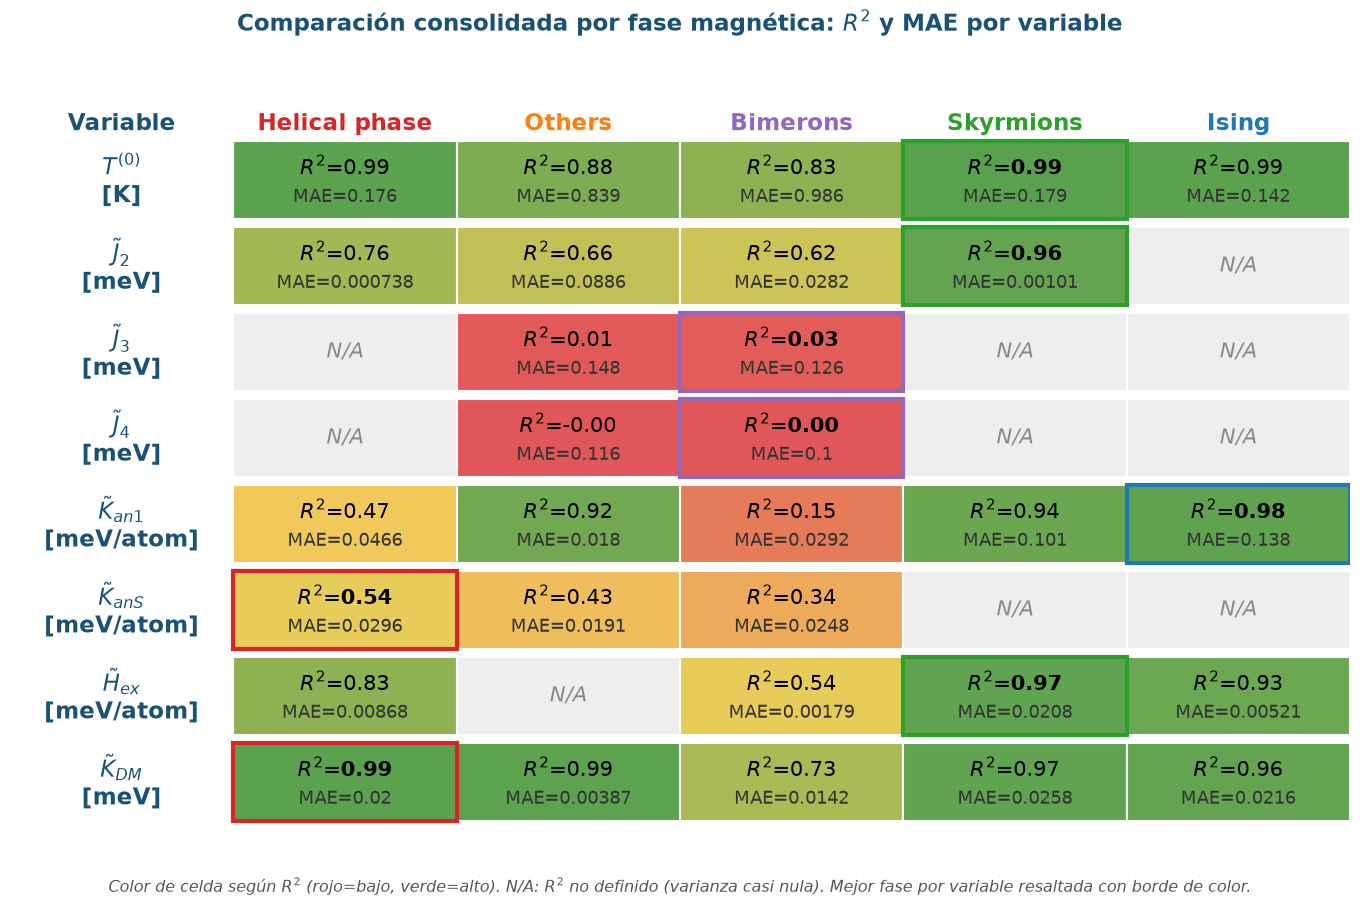

✅ Guardado en /workspace/Process/Images/metrics_by_structure_table.pdf


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Rectangle
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
import tensorflow as tf

# ══════════════════════════════════════════════════════════
# 0. ESCALAS DE FUENTE Y PALETAS
# ══════════════════════════════════════════════════════════
FONTSCALE   = 1.5
FS_SUPTITLE = 13 * FONTSCALE
FS_TITLE    = 11 * FONTSCALE
FS_LABEL    = 11 * FONTSCALE
FS_TICK     = 15 * FONTSCALE
FS_STATS    =  9 * FONTSCALE
FS_LEGEND   =  9 * FONTSCALE
FS_CELL     = 10 * FONTSCALE
FS_HEADER   = 11 * FONTSCALE
c_line      = "#1a5276"

var_colors = ["#4e79a7", "#f28e2b", "#e15759", "#76b7b2",
              "#59a14f", "#edc948", "#b07aa1", "#ff9da7"]

structure_colors = {
    "helical": "#d62728", "Others": "#ff7f0e", "Bimerones": "#9467bd",
    "Skyrmiones": "#2ca02c", "Ising": "#1f77b4",
}
structure_labels_short = {
    "helical": "Helical\nphase", "Others": "Others", "Bimerones": "Bimerons",
    "Skyrmiones": "Skyrmions", "Ising": "Ising",
}

variables = {
    r"$T^{(0)}$":         (0, "K"),
    r"$\tilde{J}_2$":     (1, "meV"),
    r"$\tilde{J}_3$":     (2, "meV"),
    r"$\tilde{J}_4$":     (3, "meV"),
    r"$\tilde{K}_{an1}$": (4, "meV/atom"),
    r"$\tilde{K}_{anS}$": (5, "meV/atom"),
    r"$\tilde{H}_{ex}$":  (6, "meV/atom"),
    r"$\tilde{K}_{DM}$":  (7, "meV"),
}
var_names = list(variables.keys())

# ══════════════════════════════════════════════════════════
# 1. RECUPERAR ETIQUETAS DE ESTRUCTURA DEL TEST SET
# ══════════════════════════════════════════════════════════
_d = np.load(DATASET_PATH, allow_pickle=True)
label_all = np.array([str(s) for s in _d['label_names']])
idx_all = np.arange(len(label_all))
idx_tr, idx_te = train_test_split(idx_all, test_size=0.15, random_state=SEED)
label_test = label_all[idx_te]
print(f"label_test: {label_test.shape}  (debe = {y_true.shape[0]})")

# ══════════════════════════════════════════════════════════
# 2. PREDICCIONES DEL MEJOR MODELO SOBRE TEST
# ══════════════════════════════════════════════════════════
best = tf.keras.models.load_model(
    f"{BASE}/modelo_xception_heteroscedastico_estructuras.keras", compile=False)

def prep_224(img, yy):
    img = tf.image.resize(img, [224, 224])
    img = tf.image.grayscale_to_rgb(img)
    return img, yy

test_ds = (tf.data.Dataset.from_tensor_slices((X_test, y_test_scaled))
           .map(prep_224, num_parallel_calls=tf.data.AUTOTUNE)
           .batch(128).prefetch(tf.data.AUTOTUNE))

y_pred_full = best.predict(test_ds, verbose=0)
y_pred_scaled = y_pred_full[:, :8]   # solo μ (heteroscedástico)
y_pred_best = scaler.inverse_transform(y_pred_scaled)
y_true_best = y_test.copy()

# ══════════════════════════════════════════════════════════
# 3. ESTRUCTURAS PRESENTES EN TEST
# ══════════════════════════════════════════════════════════
structures = ["helical", "Others", "Bimerones", "Skyrmiones", "Ising"]
structures = [s for s in structures if (label_test == s).sum() > 0]

# ══════════════════════════════════════════════════════════
# 4. MAE + R² POR ESTRUCTURA × VARIABLE (un solo dataframe)
# ══════════════════════════════════════════════════════════
VAR_THRESHOLD = 1e-4

rows_var = []
for structure in structures:
    mask = (label_test == structure)
    if mask.sum() == 0:
        continue
    for var_name, (idx, unit) in variables.items():
        yt = y_true_best[mask, idx]
        yp = y_pred_best[mask, idx]

        mae = mean_absolute_error(yt, yp)
        r2 = np.nan if yt.var() < VAR_THRESHOLD else r2_score(yt, yp)

        rows_var.append({
            "Structure": structure,
            "Variable": var_name,
            "Unit": unit,
            "MAE": mae,
            "R²": r2,
        })

var_struct_df = pd.DataFrame(rows_var)
print(var_struct_df.pivot(index="Structure", columns="Variable", values="R²").round(3).to_string())

# ══════════════════════════════════════════════════════════
# 5. FIGURA A — GRID 4×2 DE MAE POR ESTRUCTURA (escala propia)
# ══════════════════════════════════════════════════════════
NCOLS, NROWS = 4, 2
n_structs = len(structures)
bar_w = 0.55
x_base = np.arange(n_structs)

fig, axes = plt.subplots(
    NROWS, NCOLS,
    figsize=(NCOLS * 4.4, NROWS * 4.5),
    facecolor="white",
    gridspec_kw={"hspace": 0.75, "wspace": 0.45},
)
axes = axes.flatten()

for ax_i, (var_name, (idx, unit)) in enumerate(variables.items()):
    ax = axes[ax_i]
    ax.set_facecolor("white")

    sub = var_struct_df[var_struct_df["Variable"] == var_name]
    vals_all = {
        s: sub[sub["Structure"] == s]["MAE"].values[0]
        for s in structures if len(sub[sub["Structure"] == s]) > 0
    }
    best_struct = min(vals_all, key=vals_all.get)

    for s_i, structure in enumerate(structures):
        v = vals_all.get(structure, 0.0)
        ec = "#000000" if structure == best_struct else "white"
        ew = 2.5 if structure == best_struct else 0.5
        ax.bar(s_i, v, width=bar_w, color=structure_colors[structure],
               edgecolor=ec, linewidth=ew, zorder=3)

    ax.set_xticks(x_base)
    ax.set_xticklabels([structure_labels_short[s] for s in structures],
                       fontsize=FS_TICK * 0.80 / FONTSCALE * 1.3, fontweight="bold",
                       rotation=20, ha="right")
    for tick, struct in zip(ax.get_xticklabels(), structures):
        tick.set_color(structure_colors[struct])

    ax.set_title(f"{var_name}  [{unit}]", fontsize=FS_TITLE, fontweight="bold",
                 color=c_line, pad=6)
    ax.set_ylabel(f"MAE [{unit}]", color="#444444", fontsize=FS_LABEL * 0.85)
    ax.tick_params(axis="y", colors="#444444", labelsize=FS_TICK * 0.7)
    ax.tick_params(axis="x", length=0)
    ax.grid(axis="y", linestyle="--", alpha=0.35, zorder=0)
    ax.set_xlim(-0.6, n_structs - 0.4)
    ax.set_ylim(bottom=0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#cccccc")
    ax.spines["bottom"].set_visible(False)

struct_handles = [
    mpatches.Patch(facecolor=structure_colors[s], edgecolor="white",
                   linewidth=0.5, label=structure_labels_short[s].replace("\n", " "))
    for s in structures
]
best_handle = mpatches.Patch(facecolor="#bbbbbb", edgecolor="#000000",
                             linewidth=2.5, label="Best phase (per variable)")
fig.legend(handles=struct_handles + [best_handle], loc="lower center",
           ncol=len(structures) + 1, fontsize=FS_LEGEND, frameon=False,
           bbox_to_anchor=(0.5, -0.02), labelcolor="#333333",
           title="Magnetic phase", title_fontsize=FS_LEGEND)
plt.savefig(f"{OUT_DIR}/metrics_by_structure_mae_grid.pdf",
            bbox_inches="tight", facecolor="white")
plt.show()
print(f"✅ Guardado en {OUT_DIR}/metrics_by_structure_mae_grid.pdf")

# ══════════════════════════════════════════════════════════
# 6. FIGURA B — BARPLOT DE R² POR ESTRUCTURA
# ══════════════════════════════════════════════════════════
n_vars_pl = len(var_names)
bar_w = 0.09
x_structs = np.arange(len(structures))
fig, ax = plt.subplots(figsize=(13, 6), facecolor="white")
ax.set_facecolor("white")

for v_i, var_name in enumerate(var_names):
    offset = (v_i - n_vars_pl / 2 + 0.5) * bar_w
    vals = []
    for structure in structures:
        row = var_struct_df.loc[
            (var_struct_df["Structure"] == structure) &
            (var_struct_df["Variable"] == var_name), "R²"]
        val = row.values[0] if len(row) > 0 else np.nan
        vals.append(max(val, 0.0) if not np.isnan(val) else 0.0)
    ax.bar(x_structs + offset, vals, width=bar_w, label=var_name,
           color=var_colors[v_i], edgecolor="white", linewidth=0.5, zorder=3)

ax.axhline(0.85, color="#1a7a4a", linewidth=1.2, linestyle=":", alpha=0.8)
ax.axhline(0.50, color="#b85c00", linewidth=1.2, linestyle=":", alpha=0.8)
ax.text(len(structures) - 0.05, 0.86, r"$R^2=0.85$", fontsize=FS_STATS * 0.85,
        color="#1a7a4a", va="bottom", ha="right")
ax.text(len(structures) - 0.05, 0.51, r"$R^2=0.50$", fontsize=FS_STATS * 0.85,
        color="#b85c00", va="bottom", ha="right")
ax.set_xticks(x_structs)
ax.set_xticklabels([structure_labels_short[s] for s in structures],
                   fontsize=FS_TICK * 0.90, ha="center")
for tick, struct in zip(ax.get_xticklabels(), structures):
    tick.set_color(structure_colors[struct])
    tick.set_fontweight("bold")
ax.set_ylabel(r"$R^2$ Score  $\uparrow$", color="#444444", fontsize=FS_LABEL)
ax.tick_params(colors="#444444", labelsize=FS_TICK * 0.85)
ax.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
ax.set_ylim(bottom=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#cccccc")
ax.spines["bottom"].set_color("#cccccc")

var_handles = [
    mpatches.Patch(facecolor=var_colors[v_i], edgecolor="white",
                   linewidth=0.5, label=var_name)
    for v_i, var_name in enumerate(var_names)
]
fig.legend(handles=var_handles, loc="lower center", ncol=len(var_names),
           fontsize=FS_LEGEND, frameon=False, bbox_to_anchor=(0.5, -0.06),
           labelcolor="#333333", title="Hamiltonian parameter",
           title_fontsize=FS_LEGEND)
fig.text(0.5, -0.12,
         r"N/A values ($R^2$ undefined, near-zero variance) "
         r"and negative $R^2$ clipped to zero.",
         ha="center", fontsize=FS_STATS * 0.85, color="#555555", style="italic")
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.savefig(f"{OUT_DIR}/metrics_by_structure_r2.pdf",
            bbox_inches="tight", facecolor="white")
plt.show()
print(f"✅ Guardado en {OUT_DIR}/metrics_by_structure_r2.pdf")

# ══════════════════════════════════════════════════════════
# 7. FIGURA C — TABLA CONSOLIDADA (R² + MAE por estructura)
# ══════════════════════════════════════════════════════════
n_vars = len(var_names)
n_structs = len(structures)

cmap = LinearSegmentedColormap.from_list("r2cmap", ["#e15759", "#f2cf5b", "#59a14f"])

fig, ax = plt.subplots(figsize=(2.3 * n_structs + 2.2, 0.95 * n_vars + 1.5),
                        facecolor="white")
ax.set_xlim(0, n_structs + 1)
ax.set_ylim(0, n_vars + 1)
ax.axis("off")
ax.invert_yaxis()

for j, structure in enumerate(structures):
    ax.text(j + 1.5, 0.35, structure_labels_short[structure].replace("\n", " "),
             ha="center", va="center", fontsize=FS_HEADER, fontweight="bold",
             color=structure_colors[structure])

ax.text(0.5, 0.35, "Variable", ha="center", va="center",
         fontsize=FS_HEADER, fontweight="bold", color=c_line)

for v_i, var_name in enumerate(var_names):
    y = v_i + 1
    unit = variables[var_name][1]
    ax.text(0.5, y, f"{var_name}\n[{unit}]", ha="center", va="center",
             fontsize=FS_LABEL, fontweight="bold", color=c_line)

    sub = var_struct_df[var_struct_df["Variable"] == var_name]
    r2_row = {r["Structure"]: r["R²"] for _, r in sub.iterrows()}
    mae_row = {r["Structure"]: r["MAE"] for _, r in sub.iterrows()}

    valid = {s: v for s, v in r2_row.items() if not np.isnan(v)}
    best_struct = max(valid, key=valid.get) if valid else None

    for j, structure in enumerate(structures):
        x = j + 1
        r2 = r2_row.get(structure, np.nan)
        mae = mae_row.get(structure, np.nan)

        color = "#eeeeee" if np.isnan(r2) else cmap(np.clip(r2, 0, 1))
        rect = Rectangle((x, y - 0.45), 1, 0.9, facecolor=color,
                          edgecolor="white", linewidth=1.5, zorder=2)
        ax.add_patch(rect)

        if structure == best_struct:
            rect_best = Rectangle((x, y - 0.45), 1, 0.9, facecolor="none",
                                   edgecolor=structure_colors[structure],
                                   linewidth=3.0, zorder=4)
            ax.add_patch(rect_best)

        if np.isnan(r2):
            ax.text(x + 0.5, y, "N/A", ha="center", va="center",
                     fontsize=FS_CELL, color="#888888", style="italic")
        else:
            ax.text(x + 0.5, y - 0.15, f"$R^2$={r2:.2f}",
                     ha="center", va="center", fontsize=FS_CELL,
                     fontweight="bold" if structure == best_struct else "normal",
                     color="black")
            ax.text(x + 0.5, y + 0.20, f"MAE={mae:.3g}",
                     ha="center", va="center", fontsize=FS_CELL * 0.85,
                     color="#333333")

fig.suptitle("Comparación consolidada por fase magnética: $R^2$ y MAE por variable",
             fontsize=FS_TITLE, fontweight="bold", color=c_line, y=0.98)
fig.text(0.5, 0.01,
         r"Color de celda según $R^2$ (rojo=bajo, verde=alto). N/A: $R^2$ no definido "
         r"(varianza casi nula). Mejor fase por variable resaltada con borde de color.",
         ha="center", fontsize=FS_STATS * 0.85, color="#555555", style="italic")

plt.tight_layout(rect=[0, 0.02, 1, 0.95])
plt.savefig(f"{OUT_DIR}/metrics_by_structure_table.pdf", bbox_inches="tight", facecolor="white")
plt.show()
print(f"✅ Guardado en {OUT_DIR}/metrics_by_structure_table.pdf")